<h1 style="background-color:#072448; font-family:newtimeroman; color:#FFFFFF; font-size:48px; padding : 10px; margin : 0; text-align : center"><b> Customer Churn</b></h1>

In [2]:
from IPython.display import HTML
html1 = '<center><img src="Churn_image.png"><center/>'
HTML(html1)

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 1><b> Content</b></a></h1>

- <a href='#1'><b> Problem definition </b></a>
- <a href='#2'><b> Library </b></a>
- <a href='#3'><b> Aquire data </b></a>
    - <a href='#51'><b>Survived</b></a>
    - <a href='#52'><b>Sex</b></a>
- <a href='#6'><b> Split data</b></a>
- <a href='#7'><b> Model, predict and solve</b></a>

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 1><b> Problem definition</b></a></h1>

- **In this project we will explore data from a telecommunications company in order to build a machine learning model to predict the churn of the company's customers**

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 2><b> Import Package</b></a></h1>

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
# import matplotlib
import matplotlib as mpl
# default_backend = mpl.get_backend()
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

from colorama import Fore, Back, Style
from ipywidgets import interact, widgets

from scipy import stats, special
from scipy.stats import norm, skew, shapiro, kstest, pearsonr, spearmanr, kendalltau, chi2_contingency, levene

from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

# machine learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, RidgeClassifier, SGDClassifier, LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from mlxtend.classifier import StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import RFE

from sklearn.base import TransformerMixin, BaseEstimator
from sklearn.pipeline import Pipeline

seed = 1234

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 3><b> Functions</b></a></h1>

In [10]:
# Pie_chart 
def pie_chart(feature) :
    total = df[feature].value_counts().values.sum()
    explode = [0.05]*len(df[feature].unique())
    def func(pct):
        return f"{int(np.round(pct/100*total)):d}"

    piechart = plt.pie(df[feature].value_counts().values, labels = df[feature].value_counts().index, autopct = func, startangle = 90,
               explode = explode, shadow = True, textprops={'size': 12, 'color' : 'black', 'weight': 'bold'}, radius= 1)
    plt.title(label = f"{feature} Customers Distribution", fontsize = 14, color = 'white', loc = 'center', backgroundcolor='black', fontweight='bold')

# Distribution
def bar_plot_distribution(target, feature) :
    plt.figure(figsize = (10,6))
    bars = sns.countplot(data = df, x=feature, hue = target)
    
    val0 = bars.containers[0].datavalues; val0[np.isnan(val0)] = 0
    val1 = bars.containers[1].datavalues; val1[np.isnan(val1)] = 0
    
    for i, v in enumerate(val0):
        plt.text(i - 0.2  , v/2, str(int(v)), color='black', ha="center", fontweight = 'bold', fontsize = 12)
    for i, v in enumerate(val1):
        plt.text(i + 0.2  , v/2, str(int(v)), color='black', ha="center", fontweight = 'bold', fontsize = 12)
    
    plt.legend(loc='upper right', title=target, title_fontsize=12, facecolor='white', edgecolor ='black', borderpad=1, labelcolor = 'blue')
    plt.title(label =f'Churned and UnChurned Costumers by {feature}', fontsize = 14, color = 'white', backgroundcolor='black', fontweight='bold')

# Describe feature
def description (feature) :
    des = df[feature].describe().to_frame().T
    des['cardinality'] = len(df[feature].unique())
    display(des)
    print(Back.YELLOW +'\033[1m' +f'value of {feature} =  {df[feature].unique()}'+ '\033[0m' + '\n')
    display(df[[feature, target]].groupby([feature]).count().rename(columns={target: "Count"}))
    pie_chart(feature)

# Distribution categorical feature
def cat_distribution_bytarget (feature) :
    cross_tab = pd.crosstab(df[feature], df[target])
    display(cross_tab)
    bar_plot_distribution(target, feature)
    relation(target, feature)

#Distribution numeric feature  
def num_distributuion(feature, n) :
    display(df[feature].describe().to_frame().T)
    plt.figure(figsize = (12, 8))
    bins = (df[feature].max()- df[feature].min())/n
    binf = 0 ; bsup = (df[feature].max() + bins) ; biins = np.arange(binf, bsup, bins)
    feat = sns.displot(df[feature], color="blue", aspect = 2, height = 5, bins = biins)
    plt.title (f'►Customers Distribution by {feature}◄', fontsize=14, fontweight='bold')
    plt.xticks(np.arange(binf, bsup, bins))
    feats = feat.facet_axis(0,0).containers[0].datavalues
    for i, v in enumerate(feats):
        plt.text(i*bins + bins/2 , v + 1, str(v), color='black', ha="center", fontweight = 'bold') 

# Normality
def distributuion_normality(feature) :
    fig, ax = plt.subplots(2, 2, figsize=(18, 8), gridspec_kw=dict(width_ratios=[1,1], height_ratios= [4,1]))
    sns.distplot(df[feature], fit=norm, ax = ax[0][0])
    res = stats.probplot(df[feature], plot=ax[0][1])
    
    ax[1][0].text(0.1, 0.7, f'Skewness = {df[feature].skew().round(3)}', fontsize = 14, fontweight = 'bold' )
    ax[1][0].text(0.1, 0.4, f'kurtosis = {df[feature].kurt().round(3)}', fontsize = 14, fontweight = 'bold' )
    ax[1][0].text(0.1, 0.1, f'Test = {stats.normaltest(df[feature]).pvalue}', fontsize = 14, fontweight = 'bold' )
    ax[1][1].text(0.1, 0.2, f'KSTest = {stats.kstest(df[feature], "norm")[1]}', fontsize = 14, fontweight = 'bold')
    ax[1][1].text(0.1, 0.6, f'Shapiro = {shapiro(df[feature])[1]}', fontsize = 14, fontweight = 'bold')
    
    ax[1][0].set_xticks([]); ax[1][1].set_xticks([]); ax[1][0].set_yticks([]); ax[1][1].set_yticks([])

# Boxplot - Outliers
def box(feature) :
    sns.boxplot(df[feature],color="purple")
    plt.title(f"{feature} Outliers Detection",fontweight="black",pad=10,size=18)
    plt.tight_layout()
    plt.show()

# feature distribution by target
def feature_distribution_bytarget(feature) :
    boxs = sns.boxplot(data = df, x = target, y = feature)
    medians = df.groupby([target])[feature].median()
    counts =  df.groupby([target])[feature].count()
    for xtick in boxs.get_xticks():
        boxs.text(xtick,medians[xtick] ,str(medians[xtick]) + ' ' + '('+str(counts[xtick]) + ')', horizontalalignment='center',size=10,color='w',weight='semibold')

# distribution of numeric feature by target
def distribution_num_feature_bytarget(feature, n) :
    
    bins = (df[feature].max()- df[feature].min())/n
    binf = 0 ; bsup = (df[feature].max() + bins) ; biins = np.arange(binf, bsup, bins)
    
    feats = sns.displot(data=df, x=feature, hue=target, multiple="dodge", bins = biins, height=5, aspect=2)

    vals0 = feats.facet_axis(0,0).containers[0].datavalues
    vals1 = feats.facet_axis(0,0).containers[1].datavalues
    plt.xticks(np.arange(binf, bsup, bins))
    for i, v in enumerate(vals0):
        plt.text(i*bins + (3*bins/4), v/2, str(v), color='black', ha="center", fontweight = 'bold')
        plt.text(i*bins + (3*bins/4), v+40, str(round(v*100/1857, 1)) + '%', color='red', ha="center", fontweight = 'bold')
    for i, v in enumerate(vals1):
        plt.text(i*bins + (bins/4), v/2, str(v), color='black', ha="center", fontweight = 'bold')
        plt.text(i*bins + (bins/4), v+40, str(round(v*100/5164, 1))+ '%', color='red', ha="center", fontweight = 'bold')

# Numeric feature VS Target by Categorical feature
def distribution_num_feature_target_cat(feature, categoric) :
    plt.figure(figsize=(10, 6))
    sns.boxplot(x = target, y = feature, hue = categoric, data = df)
    plt.legend(loc='upper left')
    plt.show()

# Relation
def relation(target, feature) :
    cross_tab = pd.crosstab(df[feature], df[target])
    chi2_stat, p_value, _, _ = chi2_contingency(cross_tab)
    n = df.shape[0]
    s = cross_tab.sum().sum()
    min_dim = min(cross_tab.shape) - 1
    cramer_v = np.sqrt(chi2_stat / (s * min_dim)).round(2)
    tschuprow_t = np.sqrt(chi2_stat / (n * min_dim)).round(2)
    print(Back.YELLOW +'\033[1m' + f"The relation between {target} and {feature} : "+ '\033[0m' )  
    print(Back.YELLOW +'\033[1m' + f'Chie2 Test : p_value = {p_value} - Coefficient de Cramér-V = {cramer_v}   Coefficient T de Tschuprow = {tschuprow_t}'+ '\033[0m' + '\n' )

# Correlation
def correlation(feature, test) :
    df1 = df[[target,feature]].dropna()
    df1[target]= df1[target].astype('category').cat.codes
    v, p = test(df1[target], df1[feature])
    print(Back.YELLOW +Fore.BLACK + '\033[1m'+ f'correlation coefficient: {v}'+'\033[0m')
    print(Back.BLACK +Fore.WHITE + '\033[1m'+ f'P-value of correlation test: {p}' +'\033[0m')

# Fill missing value by median 
def fill_by_median (df, feature1, feature2):
    feat1 = df_mean[feature1].unique()
    feat2 = df_mean[feature2].unique()
    mean_totalcharges = np.zeros((len(feat1),len(feat2)))
    
    for f1 in feat1 :
        i = np.where(feat1 == f1)[0][0]
        for f2 in feat2:
            j = np.where(feat2 == f2)[0][0]
            mean_df = df_mean[(df_mean[feature1] == f1) & (df_mean[feature2] == f2)]['TotalCharges'].dropna().median() 
            mean_totalcharges[i, j]=mean_df
    # mean_totalcharges  
    
    for i in range(0, len(feat1)):
        f1 = feat1[i]
        for j in range(0, len(feat2)):
            f2 = feat2[j]
            if not(df_mean.loc[df_mean['TotalCharges'].isnull() & (df_mean[feature1]==f1) & (df_mean[feature2] == f2)].empty):
                df_mean.loc[df_mean['TotalCharges'].isnull() & (df_mean[feature1]==f1) & (df_mean[feature2] == f2), 'TotalCharges'] = mean_totalcharges[i,j]

# function of transformation : elle manque la verification des zero pour log
def transformation (df, transformer) :
    if transformer == 'boxcox' :
        for feature in num_col:
            df[feature], _ = stats.boxcox(df[feature])
    if transformer == 'log' :
        for feature in num_col:
            df[feature] = np.log(df[feature])
    if transformer == 'sqrt' :
        for feature in num_col:
            df[feature] = np.sqrt(df[feature])
    if transformer == 'boxcox1p' :
        for feature in num_col:
            df[feature] = special.boxcox1p(df[feature] + 1, stats.boxcox_normmax(df[feature] + 1))

def scale_data(df, algo) :
    scaler = algo
    y = df[target]
    df_array = df.values
    df = pd.DataFrame(scaler.fit_transform(df_array), columns = df.columns)
    df[target] = y
    return df

def split(df, rate) :
    X = df.drop(target, axis = 1)
    y = df[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 1 - rate, random_state = seed, stratify = y)
    # stratify = y pour avoir les memes proportions selon y
    # random_state : division se fait aleatoirement, donner une valeur a random_state permet de sauvgarder la meme division
    X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size = 0.5, random_state = seed, stratify = y_test)
    return y, X_train, y_train, X_test, y_test, X_val, y_val

# metric calculation without cross validation score and kfold cv average score
def metrics_calcul (model, y_test_pred) :
    MAE = mean_absolute_error(y_test,y_test_pred)
    MSE = mean_squared_error(y_test,y_test_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_test,y_test_pred)
    ADJUST_R2 = 1 - ((1-R2)*(X_test.shape[0]-1)/(X_test.shape[0]-X_test.shape[1]-1))
    score = model.score(X_train, y_train)

    metrics = {'R2 Score' : R2, 
              'Adjusted R2 Score' : ADJUST_R2,
              'MAE' : MAE, 
              'MSE' : MSE,
              'RMSE' : RMSE,
              'Training score' : score
              }
    metrics = pd.DataFrame(metrics, index = [0])
    display(metrics)

# model training 
def model_training(model):
    model.fit(X_train, y_train)
    y_train_pred= model.predict(X_train)
    y_test_pred = model.predict(X_test)
  
    metrics_calcul(model, y_test_pred)
    print('*****************************************************************')
    
    plt.figure(figsize=(15,5))
    cm = confusion_matrix(y_test, y_test_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.title('Confusion matrix',fontweight="black",size=20,pad=10)
        
    report = classification_report(y_val, model.predict(X_val), output_dict=True)
    class_report = pd.DataFrame(report).transpose()
    print(class_report)


<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 4><b> Aquire data</b></a></h1>

In [12]:
df = pd.read_csv('Customer_Churn.csv') 
#df1 = pd.read_csv('https://github.com/JosueAfouda/TUTORIALS/blob/main/Telco-Customer-Churn.csv')

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 5><b> Describe data</b></a></h1>

In [14]:
df.shape

(7043, 21)

- <b> We have 7043 costumers in our dataset 

In [16]:
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6232,9681-OXGVC,Female,0,No,No,5,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.50,514,Yes
5549,0329-GTIAJ,Female,0,No,No,3,Yes,No,Fiber optic,No,...,No,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,97.90,315.3,Yes
1852,3669-OYSJI,Male,0,No,No,1,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,No,Credit card (automatic),46.20,46.2,Yes
6027,4896-CPRPF,Male,0,Yes,Yes,35,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),25.45,809.25,No
5077,8314-HTWVE,Female,0,Yes,Yes,7,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,144.15,No


In [17]:
print(df.columns.values)

['customerID' 'gender' 'SeniorCitizen' 'Partner' 'Dependents' 'tenure'
 'PhoneService' 'MultipleLines' 'InternetService' 'OnlineSecurity'
 'OnlineBackup' 'DeviceProtection' 'TechSupport' 'StreamingTV'
 'StreamingMovies' 'Contract' 'PaperlessBilling' 'PaymentMethod'
 'MonthlyCharges' 'TotalCharges' 'Churn']


- **We have 21 feautures in dataset includes customerID and the target Churn**
- **The target variable is the churn variable which takes two values `Yes` for customers who are churned and `No` for customers who are not churned**

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


- **We dont have blank, null or empty values**
- **Three features are integers or floats : SeniorCitizen, tenure, MonthlyCharges  -- 18 features are objects**
    - **customerID is like index, so it is not usefull, we drop it**
    - **16 features are categoricals**
    - **TotalCharges should be float but it is an object. we deal this column**</b>

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 31><b> Drop customerID And Deal TotalCharges </b></a></h2>

In [22]:
# Drop custumerID 
df.drop('customerID', axis = 1, inplace=True)

In [23]:
df['TotalCharges'].values
# TatalCharges values are string

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      dtype=object)

In [24]:
# Convert TotalCharges Values to float
try :
    pd.to_numeric(df.TotalCharges)
except:
    print('unable to convert totalCharges to float')

unable to convert totalCharges to float


- **Unable to convert it, we return error**

In [26]:
# Why cant convert TotalCharges Values to float
df[pd.to_numeric(df.TotalCharges,errors='coerce').isnull()]['TotalCharges'].values

array([' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
      dtype=object)

- **Some values in TotalCharges Column are ' '**

In [28]:
# Replace there values by nan
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)

In [29]:
# Convert now TotalCharges values to float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 32><b> Duplicated rows </b></a></h2>

In [31]:
df.duplicated().sum() # 22
# we have 22 duplicated rows

22

In [32]:
df[df.duplicated(keep=False)].head()
# for example (row 22 and row 1338) and (row 1731 and row 3301)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
22,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
100,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.20,20.20,No
542,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
646,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes
662,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No


In [33]:
df.iloc[[22, 1338]]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
22,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
1338,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes


In [34]:
df.iloc[[1731, 3301]]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1731,Female,1,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.6,69.6,Yes
3301,Female,1,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.6,69.6,Yes


In [35]:
# we drop duplicated rows
df = df[df.duplicated()== False]
df.shape

(7021, 20)

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 6><b> Exploring data</b></a></h1>

In [37]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7021.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00
tenure,7021.0,32.47,24.53,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7021.0,64.85,30.07,18.25,35.75,70.40,89.90,118.75
TotalCharges,7010.0,2290.35,2266.82,18.80,408.31,1403.88,3807.84,8684.80


* **Continuous features `TotalCharges`,`MonthlyCharges` and `tenure` are having `high deviation` values. So we have to use `transformation and scaling technique` to reduce the deviation**
* **`SeniorCitizen` is a 0 or 1, like categorical feature**

In [39]:
df.describe(include=['O']).T

,count,unique,top,freq
gender,7021,2,Male,3541
Partner,7021,2,No,3619
Dependents,7021,2,No,4911
PhoneService,7021,2,Yes,6339
MultipleLines,7021,3,No,3368
InternetService,7021,3,Fiber optic,3090
OnlineSecurity,7021,3,No,3490
OnlineBackup,7021,3,No,3080
DeviceProtection,7021,3,No,3087
TechSupport,7021,3,No,3465


- **We have not a `heigt cardinality` in our dataset [2 - 3 - 4]**

In [41]:
target = 'Churn'

In [42]:
num_col = df.describe().columns.drop('SeniorCitizen')
num_col

Index(['tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

In [43]:
cat_col = df.describe(include=['O']).columns.union(['SeniorCitizen']).drop('Churn')
cat_col

Index(['Contract', 'Dependents', 'DeviceProtection', 'InternetService',
       'MultipleLines', 'OnlineBackup', 'OnlineSecurity', 'PaperlessBilling',
       'Partner', 'PaymentMethod', 'PhoneService', 'SeniorCitizen',
       'StreamingMovies', 'StreamingTV', 'TechSupport', 'gender'],
      dtype='object')

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 41><b> Target : Churn </b></a></h2>

In [45]:
df[target].describe().to_frame().T

,count,unique,top,freq
Churn,7021,2,No,5164


In [46]:
print(Back.YELLOW +'\033[1m' +f'value of {target} =  {df[target].unique()}'+ '\033[0m' + '\n')

value of Churn =  ['No' 'Yes']



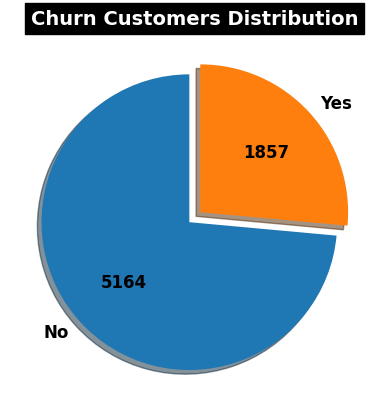

In [47]:
# distribution of Churned and Unchurned customers
pie_chart(target)

- **5164/7021 of customers are not churned (73.5%) - 1857/7021 customers are churned (26.5%)**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 42><b> Categorical Features </b></a></h2>

In [50]:
cat_col

Index(['Contract', 'Dependents', 'DeviceProtection', 'InternetService',
       'MultipleLines', 'OnlineBackup', 'OnlineSecurity', 'PaperlessBilling',
       'Partner', 'PaymentMethod', 'PhoneService', 'SeniorCitizen',
       'StreamingMovies', 'StreamingTV', 'TechSupport', 'gender'],
      dtype='object')

In [51]:
# Describe   
interact(description, feature= cat_col)

interactive(children=(Dropdown(description='feature', options=('Contract', 'Dependents', 'DeviceProtection', '…

<function __main__.description(feature)>

- **PhoneService has a certain class imballance**

In [53]:
# distribution of customers by target and categorical feature 
# Chie2 test of relation between target and categorical feature
interact(cat_distribution_bytarget, feature= cat_col)

interactive(children=(Dropdown(description='feature', options=('Contract', 'Dependents', 'DeviceProtection', '…

<function __main__.cat_distribution_bytarget(feature)>

In [54]:
# The Cramer coefficient of relation between target and categorical features
coef = []
for feature in cat_col :
    cross_tab = pd.crosstab(df[feature], df[target])
    chi2_stat, p_value, _, _ = chi2_contingency(cross_tab)
    n = df.shape[0]
    s = cross_tab.sum().sum()
    min_dim = min(cross_tab.shape) - 1
    cramer_v = np.sqrt(chi2_stat / (s * min_dim)).round(2)
    coef.append(cramer_v) 
rel = pd.DataFrame({'coefficient': coef}, index = cat_col.to_numpy())
rel = rel.sort_values(by=['coefficient'], ascending=False)
rel.T

,Contract,OnlineSecurity,TechSupport,InternetService,PaymentMethod,OnlineBackup,DeviceProtection,StreamingMovies,StreamingTV,PaperlessBilling,Dependents,Partner,SeniorCitizen,MultipleLines,PhoneService,gender
coefficient,0.41,0.35,0.34,0.32,0.3,0.29,0.28,0.23,0.23,0.19,0.16,0.15,0.15,0.04,0.01,0.01


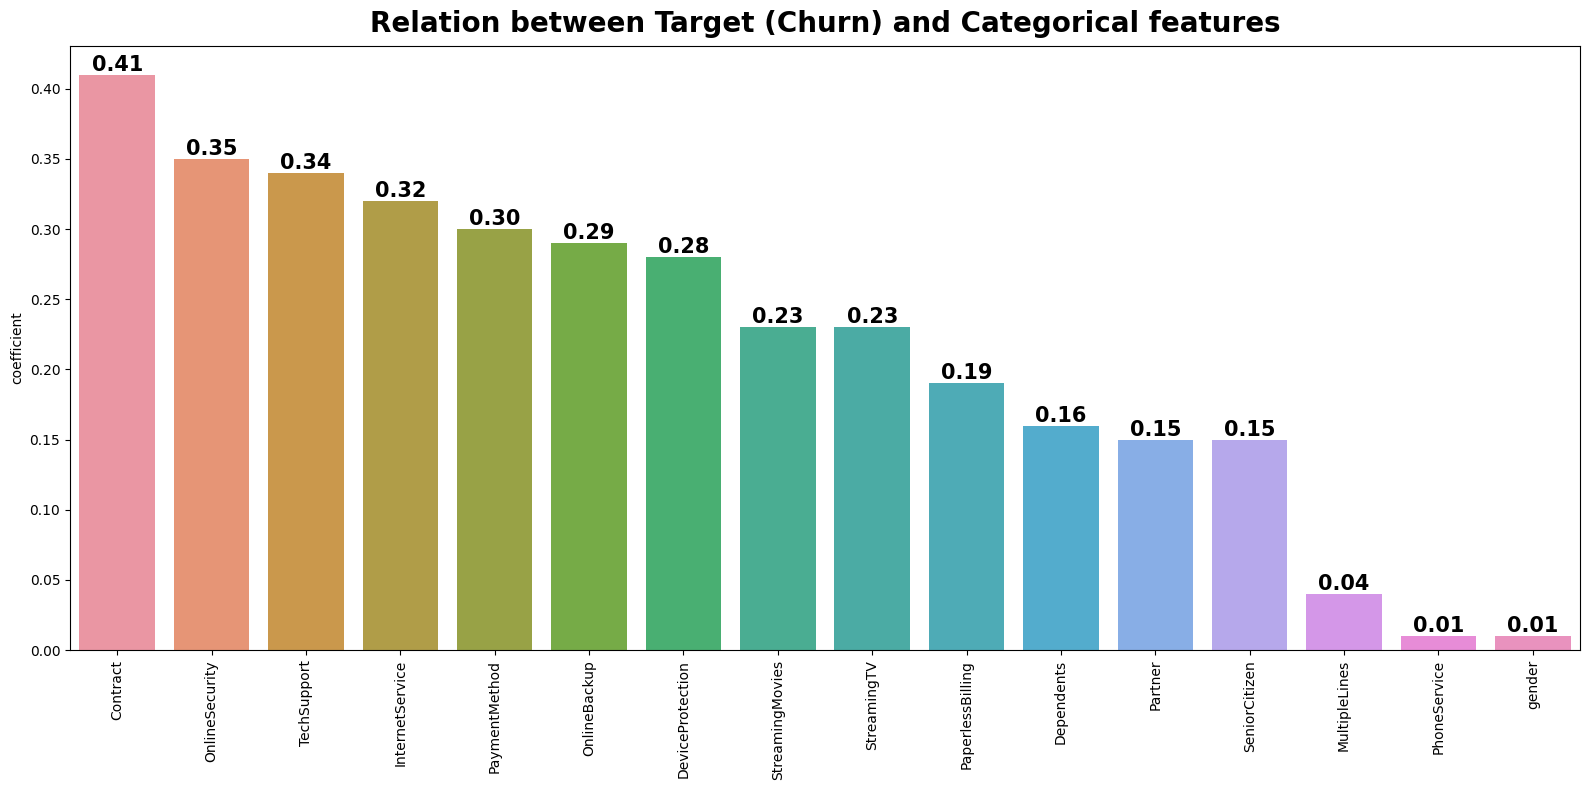

In [55]:
# The Cramer coefficient of relation between target and categorical features in the graph
plt.figure(figsize=(16,8))
sns.barplot(rel, x= rel.index, y = 'coefficient')
i = 0
for v in rel['coefficient']:
   plt.text(i, v, f"{v:.2f}", ha="center", va="bottom",size=15,fontweight="black")
   i = i +1

plt.title("Relation between Target (Churn) and Categorical features",fontweight="black",size=20,pad=10)
plt.xticks(rotation=90)
plt.tight_layout()

- **features like `Contract`, `OnlineSecurity` and `TechSupport` have a `heigt` relation with the target Churn**
- **while features like `gender`, `PhoneService` and `MultipleLines` have a `insignificant` and negligible relation with target Churn**

- **(StreamingMovies and StreamingTV) have same relation with target. Verify that are not in linearity**
- **Also (Partner and SeniorCitizen) have same relation with target. Verify that features are not in linearity**

In [58]:
relation('StreamingMovies', 'StreamingTV')  # no lineaires

The relation between StreamingMovies and StreamingTV : 
Chie2 Test : p_value = 0.0 - Coefficient de Cramér-V = 0.77   Coefficient T de Tschuprow = 0.77



In [59]:
relation('Partner', 'SeniorCitizen') # no lineaires

The relation between Partner and SeniorCitizen : 
Chie2 Test : p_value = 0.20379336478125257 - Coefficient de Cramér-V = 0.02   Coefficient T de Tschuprow = 0.02



<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 43><b> Numeric Features </b></a></h2>

### <b> Feature Distribution </b>

In [62]:
# Distribution        
interact(num_distributuion, feature= num_col, n = 8)

interactive(children=(Dropdown(description='feature', options=('tenure', 'MonthlyCharges', 'TotalCharges'), va…

<function __main__.num_distributuion(feature, n)>

### <b> Normality </b>

In [64]:
# Normality    
interact(distributuion_normality, feature= num_col)

interactive(children=(Dropdown(description='feature', options=('tenure', 'MonthlyCharges', 'TotalCharges'), va…

<function __main__.distributuion_normality(feature)>

- **All features dont have normal distribution**

### <b> Outliers </b>

In [67]:
# boxplot (Outliers)
interact(box, feature= num_col)

interactive(children=(Dropdown(description='feature', options=('tenure', 'MonthlyCharges', 'TotalCharges'), va…

<function __main__.box(feature)>

- **According to the boxplots we do not detect outliers**

### <b> Feature Distribution by Target class </b>

In [70]:
interact (feature_distribution_bytarget, feature = num_col)

interactive(children=(Dropdown(description='feature', options=('tenure', 'MonthlyCharges', 'TotalCharges'), va…

<function __main__.feature_distribution_bytarget(feature)>

- **We have 5164 No churn costumers, and 1857 churn costumers. The median of tenure of No churn costumers is 38, heigher than the median of tenure of churn customers 10**
- **The median of MonthlyCharges of churn costumers is 79.7, heigher than the median of MonthlyCharges of No churn customers  64.5**
- **The median of TotalCharges of No churn costumers is 1688.9, heigher than the median of MonthlyCharges of churn customers  713.1**

In [72]:
# distributio of numeric features by target
interact (distribution_num_feature_bytarget, feature = num_col, n =widgets.IntSlider(min=2, max=12, step=1, value=6))

interactive(children=(Dropdown(description='feature', options=('tenure', 'MonthlyCharges', 'TotalCharges'), va…

<function __main__.distribution_num_feature_bytarget(feature, n)>

- **more than 53% of churn customers have a less then 12 months tenure**
- **more than 25% of No churn customers have a monthly charges between 12.6 and 25.1**
- **more than 60% of churn customer have a monthly charges between 67 and 100.5**
- **46% of no churn customers and 65.8% of churn customers have Total charges less than 1444**

### <b> Feature Distribution by Target class and Categorical feature </b>

In [75]:
# Numeric feature VS Target by Categorical feature   
interact (distribution_num_feature_target_cat, feature = num_col, categoric = cat_col)

interactive(children=(Dropdown(description='feature', options=('tenure', 'MonthlyCharges', 'TotalCharges'), va…

<function __main__.distribution_num_feature_target_cat(feature, categoric)>

### <b>Correlation feature/target </b>

In [77]:
interact(correlation, feature = num_col, test = {'pearsonr' : pearsonr, 'spearmanr': spearmanr, 'kendalltau' : kendalltau} )

interactive(children=(Dropdown(description='feature', options=('tenure', 'MonthlyCharges', 'TotalCharges'), va…

<function __main__.correlation(feature, test)>

In [78]:
def graph_correlation (method):
    df1 = df[num_col.union([target])]
    df1[target]= df1[target].astype('category').cat.codes
    corr = df1.corr(method=method)[target].loc[num_col]
    plt.figure(figsize=(10,6))
    sns.barplot(x = corr.index, y = corr.values, palette=["lightcoral" if v < 0 else "lightgreen" for v in corr])
    for i, v in enumerate(corr):
        plt.text(i, v/2, f"{v:.2f}", ha="center", va="bottom",size=15,fontweight="black")
    plt.title("Coorelation of Discrets features w.r.t SalePrice",fontweight="black",size=20,pad=10)
    plt.xticks(ticks = np.arange(len(num_col)), labels = num_col, color = 'red')
    plt.tight_layout()
interact (graph_correlation, method = ['pearson', 'spearman', 'kendall'])

interactive(children=(Dropdown(description='method', options=('pearson', 'spearman', 'kendall'), value='pearso…

<function __main__.graph_correlation(method)>

- **`tenure` and `TotalCharges` have `negatives` correlations with target, `MonthlyCharges` have a `positive` correlation with target**
- **tenure have the most imprtant correlation with target -0.35**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 44><b> Profile Report </b></a></h2>

- **Why not use a tool like `ProfileReport`**

In [82]:
from ydata_profiling import ProfileReport
profile_df = ProfileReport(df)
profile_df

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [83]:
profile = ProfileReport(df, title="Exploratory data analysis with data profiling", html={'style':{'full_width':True}})
profile.to_file(output_file = "data profile.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 7><b> Pretraitement</b></a></h1>

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 71><b> Valeurs manquantes </b></a></h2>

In [86]:
# Approch 1 : delete missing values
df_del = df.copy()
df_del.dropna(inplace = True)
df_del.reset_index(drop=True, inplace = True)

In [87]:
# Approch 2 : fill missing values with median by some features 
feature1 = 'Contract'
feature2 = 'OnlineSecurity'
df_mean = df.copy()
fill_by_median (df_mean, feature1, feature2)
df_mean.reset_index(drop=True, inplace = True)

- **We continue to work with `df_del` in this step**
- **In others experiences we try `df_mean`**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 72><b> Normalite et transformation </b></a></h2>

- **we can use many transformation `(sqrt, log, boxcox, boxcox1p, ...)`**
- **In our dataset df_del, numeric features have `positifs values`, so we can use all transformation**
- **In this experince we use `log` transformation**

In [91]:
df_del_transformed = df_del.copy()
transformation(df_del_transformed, 'log')
df_del_transformed.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,0.000000,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,3.396185,3.396185,No
1,Male,0,No,No,3.526361,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,4.042174,7.544068,No
2,Male,0,No,No,0.693147,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,3.986202,4.683519,Yes
3,Male,0,No,No,3.806662,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),3.744787,7.517928,No
4,Female,0,No,No,0.693147,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,4.258446,5.021575,Yes


In [92]:
# we can view the distribution of features after transformation
transformed = df_del.copy()
def plotvariale(feature) : 
    transformed[feature] = np.sqrt(transformed[feature])
    print("Skewness: %f" % transformed[feature].skew())
    print("Kurtosis : ", transformed[feature].kurt().round(3))
    print(stats.normaltest(transformed[feature]))
    print(kstest(df_del[feature], 'norm'))

    plt.figure(figsize=(14,8))
    plt.subplot(1,2,1) ## means 1 row , 2 columns and 1st plot
    transformed[feature].hist(bins=30)
    
    plt.subplot(1,2,2)
    stats.probplot(transformed[feature], dist="norm", plot=plt)
    plt.show()
    
interact (plotvariale, feature = num_col)

interactive(children=(Dropdown(description='feature', options=('tenure', 'MonthlyCharges', 'TotalCharges'), va…

<function __main__.plotvariale(feature)>

- **We reduce diviation of features but not yet in normal distribution** 

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 73><b> Encodage </b></a></h2>

In [95]:
# we convert target
df_del_transformed[target]= df_del_transformed[target].astype('category').cat.codes

In [96]:
# we convert categorical features how have cardinality = 2 
for feature in cat_col :
    if df_del_transformed[feature].nunique() == 2 :
        df_del_transformed[feature]= df_del_transformed[feature].astype('category').cat.codes

In [97]:
# we use get_dummies for others categorical features
cat_vars = df_del_transformed[cat_col].nunique()[df_del_transformed[cat_col].nunique()>2].keys().to_list()
col_dummies = pd.get_dummies(data = df_del_transformed[cat_vars], drop_first= True, dtype=int, columns = cat_vars)
df_del_transformed = pd.concat([df_del_transformed, col_dummies], axis = 1).drop(cat_vars, axis = 1)

In [98]:
df_del_transformed.head(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,OnlineSecurity_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,StreamingMovies_No internet service,StreamingMovies_Yes,StreamingTV_No internet service,StreamingTV_Yes,TechSupport_No internet service,TechSupport_Yes
0,0,0,1,0,0.000000,0,1,3.396185,3.396185,0,...,0,0,1,0,0,0,0,0,0,0
1,1,0,0,0,3.526361,1,0,4.042174,7.544068,0,...,1,0,0,1,0,0,0,0,0,0
2,1,0,0,0,0.693147,1,1,3.986202,4.683519,1,...,1,0,0,1,0,0,0,0,0,0
3,1,0,0,0,3.806662,0,0,3.744787,7.517928,0,...,1,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0.693147,1,1,4.258446,5.021575,1,...,0,0,1,0,0,0,0,0,0,0


<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 74><b> Class Imbalance </b></a></h2>

In [100]:
# Approach up
minority = df_del_transformed.loc[df_del_transformed[target] == 1]
majority = df_del_transformed[df_del_transformed[target] == 0]
minority = resample(minority, replace = True, n_samples = len(majority), random_state = seed)
df_del_transformed_up = pd.concat([majority, minority])

In [101]:
# we verify solving class imbalance
df_del_transformed_up[target].value_counts(normalize = True)

Churn
0    0.5
1    0.5
Name: proportion, dtype: float64

In [102]:
df_del_transformed_up.head(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,OnlineSecurity_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,StreamingMovies_No internet service,StreamingMovies_Yes,StreamingTV_No internet service,StreamingTV_Yes,TechSupport_No internet service,TechSupport_Yes
0,0,0,1,0,0.000000,0,1,3.396185,3.396185,0,...,0,0,1,0,0,0,0,0,0,0
1,1,0,0,0,3.526361,1,0,4.042174,7.544068,0,...,1,0,0,1,0,0,0,0,0,0
3,1,0,0,0,3.806662,0,0,3.744787,7.517928,0,...,1,0,0,0,0,0,0,0,0,1
6,1,0,0,1,3.091042,1,1,4.489759,7.575277,0,...,0,1,0,0,0,0,0,1,0,0
7,0,0,0,0,2.302585,0,0,3.392829,5.710096,0,...,1,0,0,1,0,0,0,0,0,0


In [103]:
df_del_transformed_up.reset_index(drop=True, inplace = True)

In [104]:
# Approach down
minority = df_del_transformed.loc[df_del_transformed.Churn == 1]
majority = df_del_transformed[df_del_transformed.Churn == 0]
majority = resample(majority, replace = False, n_samples = len(minority), random_state = seed)
df_del_transformed_down = pd.concat([majority, minority])

In [105]:
# we verify solving class imbalance
df_del_transformed_down[target].value_counts(normalize = True)

Churn
0    0.5
1    0.5
Name: proportion, dtype: float64

In [106]:
df_del_transformed_down.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,OnlineSecurity_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,StreamingMovies_No internet service,StreamingMovies_Yes,StreamingTV_No internet service,StreamingTV_Yes,TechSupport_No internet service,TechSupport_Yes
768,1,0,0,0,2.397895,1,1,3.017983,5.469325,0,...,0,1,0,0,1,0,1,0,1,0
6303,1,0,0,0,3.332205,1,1,4.513603,7.817485,0,...,0,0,0,0,0,0,0,1,0,1
5099,0,0,1,0,3.737670,1,1,4.453184,8.224096,0,...,0,1,0,0,0,0,0,0,0,1
4367,1,0,0,0,3.044522,1,1,3.013081,6.046663,0,...,0,0,0,1,1,0,1,0,1,0
5139,1,0,0,0,4.276666,1,0,3.208825,7.483019,0,...,0,0,0,0,1,0,1,0,1,0


In [107]:
df_del_transformed_down.reset_index(drop=True, inplace = True)

- **We can others approaches like `smote` class**
- **We can now use to continue working with df_del_transformed_down or df_del_transformed_up**
- **In this experince we continue working without solving calss imbalance, so we continue working with df_del_transformed**
- **In others experinces we use df_del_transformed_down and df_del_transformed_up**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 75><b> PCA </b></a></h2>

- **We have 31 features in our dataset, we want to reduce this number without loss of significant information, so we can use pca**

In [111]:
#df_del_transformed.reset_index(drop=True, inplace = True)
pca = PCA(n_components = 0.9)
df_del_transformed_pca = pca.fit_transform(df_del_transformed.drop(target, axis = 1))
df_del_transformed_pca = pd.DataFrame(df_del_transformed_pca)
df_del_transformed_pca.head()

,0,1,2,3,4,5,6,7,8,9,10,11
0,4.342817,-1.614800,0.877256,0.153074,0.853176,0.823467,0.490740,-0.645031,0.273795,0.108540,0.940742,0.549660
1,-0.682257,0.179763,0.882039,-0.973113,-0.003992,-0.555955,-0.587913,0.965544,-0.413231,0.011798,-0.441647,-0.115436
2,2.979388,-1.307675,0.878833,-0.176967,-0.283899,-0.529026,-0.589388,0.010774,0.084098,0.918006,0.580940,0.124629
3,-0.920686,0.229865,1.565876,-1.316875,0.347303,-0.402961,0.101004,0.392601,-0.202056,-0.424733,-0.128496,-0.431455
4,2.754809,-1.705420,-0.502992,-0.196054,0.131424,0.569874,-0.182871,-0.266063,-0.010714,-0.004825,-0.059153,-0.323669


In [112]:
# we add target column
df_del_transformed_pca[target] = df_del_transformed[target]
df_del_transformed_pca.head(1)

,0,1,2,3,4,5,6,7,8,9,10,11,Churn
0,4.342817,-1.6148,0.877256,0.153074,0.853176,0.823467,0.49074,-0.645031,0.273795,0.10854,0.940742,0.54966,0


In [113]:
print(df_del_transformed.shape) # 7010*31
df_del_transformed_pca.shape # 7010*13

(7010, 31)


(7010, 13)

- **We reduce the number of feature from 31 to 13**
- **We continue working without pca, we use it in others experiences**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 76><b> Scaling </b></a></h2>

- **We can use many algorithm for scaling our data, like StandarScaler(), MinMaxScaler(), RobustScaler(), ...**
- **In this experience we use `StandardScaler()`**

In [117]:
df_del_transformed_scaled = scale_data(df_del_transformed, StandardScaler())
df_del_transformed_scaled

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,OnlineSecurity_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,StreamingMovies_No internet service,StreamingMovies_Yes,StreamingTV_No internet service,StreamingTV_Yes,TechSupport_No internet service,TechSupport_Yes
0,-1.008596,-0.440921,1.032482,-0.653764,-2.222838,-3.051036,0.828195,-1.059064,-2.304240,0,...,-0.635140,-0.526403,1.404136,-0.541185,-0.523086,-0.798895,-0.523086,-0.792201,-0.523086,-0.640674
1,0.991477,-0.440921,-0.968540,-0.653764,0.455144,0.327757,-1.207445,0.029737,0.384777,0,...,1.574455,-0.526403,-0.712182,1.847798,-0.523086,-0.798895,-0.523086,-0.792201,-0.523086,-0.640674
2,0.991477,-0.440921,-0.968540,-0.653764,-1.696449,0.327757,0.828195,-0.064602,-1.469678,1,...,1.574455,-0.526403,-0.712182,1.847798,-0.523086,-0.798895,-0.523086,-0.792201,-0.523086,-0.640674
3,0.991477,-0.440921,-0.968540,-0.653764,0.668011,-3.051036,-1.207445,-0.471502,0.367831,0,...,1.574455,-0.526403,-0.712182,-0.541185,-0.523086,-0.798895,-0.523086,-0.792201,-0.523086,1.560857
4,-1.008596,-0.440921,-0.968540,-0.653764,-1.696449,0.327757,0.828195,0.394258,-1.250521,1,...,-0.635140,-0.526403,1.404136,-0.541185,-0.523086,-0.798895,-0.523086,-0.792201,-0.523086,-0.640674
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7005,0.991477,-0.440921,1.032482,1.529603,0.190634,0.327757,0.828195,0.700763,0.418535,0,...,1.574455,-0.526403,-0.712182,1.847798,-0.523086,1.251729,-0.523086,1.262305,-0.523086,1.560857
7006,-1.008596,-0.440921,1.032482,1.529603,1.024940,0.327757,0.828195,1.031745,1.266538,0,...,-0.635140,1.899687,-0.712182,-0.541185,-0.523086,1.251729,-0.523086,1.262305,-0.523086,-0.640674
7007,-1.008596,-0.440921,1.032482,1.529603,-0.401833,-3.051036,0.828195,-1.073239,-0.714930,0,...,1.574455,-0.526403,1.404136,-0.541185,-0.523086,-0.798895,-0.523086,-0.792201,-0.523086,-0.640674
7008,0.991477,2.267980,1.032482,-0.653764,-1.170061,0.327757,0.828195,0.480235,-0.794148,1,...,-0.635140,-0.526403,-0.712182,1.847798,-0.523086,-0.798895,-0.523086,-0.792201,-0.523086,-0.640674


<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 77><b>Split data </b></a></h2>

In [119]:
# Train dataset (60%), validation dataset (20%) and test dataset (20%)
y, X_train, y_train, X_test, y_test, X_val, y_val = split(df_del_transformed_scaled, 0.6)

In [120]:
# we can verify the frequence of classes in y, its same in tain and test and validation
pd.DataFrame(y).value_counts(normalize=True)
pd.DataFrame(y_test).value_counts(normalize=True)
pd.DataFrame(y_train).value_counts(normalize=True)
pd.DataFrame(y_val).value_counts(normalize=True)

Churn
0        0.735378
1        0.264622
Name: proportion, dtype: float64

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 8><b> Modelisation</b></a></h1>

- **We are in a `classification` situation, so we use a classification machine learning model**
- **We try first`CatBoostClassifier()`**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 81><b> CatBoostClassifier() </b></a></h2>

,R2 Score,Adjusted R2 Score,MAE,MSE,RMSE,Training score
0,0.044989,0.024092,0.186163,0.186163,0.431466,0.877794


*****************************************************************
              precision    recall  f1-score      support
0              0.838302  0.900097  0.868101  1031.000000
1              0.650847  0.517520  0.576577   371.000000
accuracy       0.798859  0.798859  0.798859     0.798859
macro avg      0.744575  0.708809  0.722339  1402.000000
weighted avg   0.788697  0.798859  0.790957  1402.000000


<Figure size 1500x500 with 0 Axes>

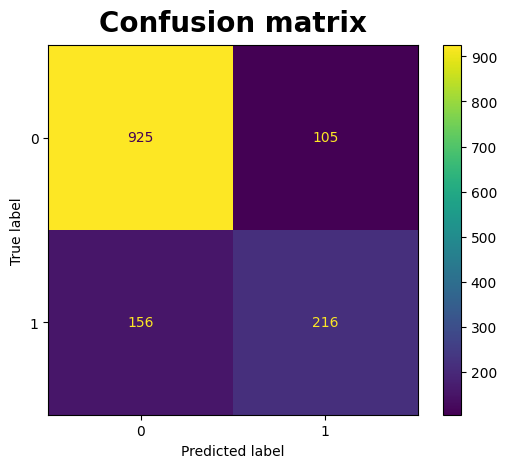

In [124]:
model_training(CatBoostClassifier(verbose = 0))

- **With this model we have an accuracy of around 80%, 261 errors on a sample of 1402**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 82><b> Others ML models </b></a></h2>

- **We can try many others classification ML models** 

In [128]:
interact(model_training, model = { 
                        'SGDClassifier()' : SGDClassifier(),
                        'RidgeClassifier()' : RidgeClassifier(), 
                        'RandomForestClassifier()': RandomForestClassifier(), 
                        'DecisionTreeClassifier()' : DecisionTreeClassifier(),
                        'GradientBoostingClassifier()':GradientBoostingClassifier(),
                        'AdaBoostClassifier()': AdaBoostClassifier(),
                        'LGBMClassifier()' : LGBMClassifier(verbose = -1), 
                        'KNeighborsClassifier()' : KNeighborsClassifier(),
                        'LogisticRegression()' : LogisticRegression()
                                  })

interactive(children=(Dropdown(description='model', options={'SGDClassifier()': SGDClassifier(), 'RidgeClassif…

<function __main__.model_training(model)>

- **Observing these results, we can keep three models with an accuracy of around 80%, CatBoostClassifier(), AdaBoostClassifier() and LogisticRegression() with a total number of errors, consecutively 261, 260 and 255 on a sample of 1402**
- **RidgeClassifier give  only 89 errors (True False prediction) but 177 errors (False True prediction)**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 83><b> Best models </b></a></h2>

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 831><b> Logistic Regression </b></a></h3>

In [132]:
# hyperparameter max_iter, C
param_grid = {'max_iter' : [100, 300, 500, 700],'C' : [0.001, 0.01, 1, 10, 50, 100] }
# GridSearchCV
grid_logisticRegression = GridSearchCV(estimator=LogisticRegression(random_state = seed), param_grid = param_grid, scoring = 'f1', cv = 5)
# Train model
LogisticRegression_grid = grid_logisticRegression.fit(X_train, y_train)
# best model
print(round(LogisticRegression_grid.best_score_, 3))
LogisticRegression_grid.best_estimator_

0.584


LogisticRegression(C=10, random_state=1234)

- **The best for logistic Regression is with C = 10, LogisticRegression(C=10, random_state=seed)**

,R2 Score,Adjusted R2 Score,MAE,MSE,RMSE,Training score
0,0.070602,0.050265,0.18117,0.18117,0.42564,0.805516


*****************************************************************
              precision    recall  f1-score      support
0              0.838104  0.908826  0.872034  1031.000000
1              0.669014  0.512129  0.580153   371.000000
accuracy       0.803852  0.803852  0.803852     0.803852
macro avg      0.753559  0.710478  0.726093  1402.000000
weighted avg   0.793359  0.803852  0.794795  1402.000000


<Figure size 1500x500 with 0 Axes>

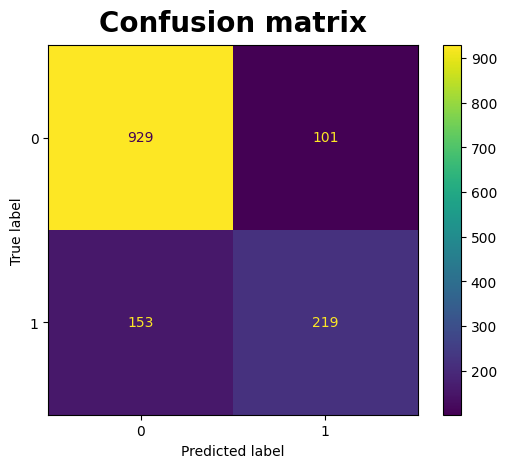

In [134]:
model_training(LogisticRegression_grid.best_estimator_)

- **The best model give an accuracy 80% and 254 errors on sample of 1402**

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 832><b> AdaBoostClassifier() </b></a></h3>

In [137]:
# hyperparameter max_iter, C
param_grid = {'algorithm' : ['SAMME.R', 'SAMME'], 'learning_rate' : [0.005, 0.01, 0.05, 1, 10] }
# GridSearchCV
grid_AdaBoostClassifier = GridSearchCV(estimator=AdaBoostClassifier(random_state = seed), param_grid = param_grid, scoring = 'f1', cv = 5)
# Train model
AdaBoostClassifier_grid = grid_AdaBoostClassifier.fit(X_train, y_train)
# best model
print(round(AdaBoostClassifier_grid.best_score_, 3))
AdaBoostClassifier_grid.best_estimator_

0.579


AdaBoostClassifier(learning_rate=1, random_state=1234)

- **The best for AdaBoostClassifier is with learning rate = 1, AdaBoostClassifier(learning_rate=1, random_state=seed)**

,R2 Score,Adjusted R2 Score,MAE,MSE,RMSE,Training score
0,0.048648,0.027831,0.185449,0.185449,0.430638,0.809082


*****************************************************************
              precision    recall  f1-score      support
0              0.838329  0.895247  0.865854  1031.000000
1              0.641196  0.520216  0.574405   371.000000
accuracy       0.796006  0.796006  0.796006     0.796006
macro avg      0.739762  0.707731  0.720129  1402.000000
weighted avg   0.786163  0.796006  0.788730  1402.000000


<Figure size 1500x500 with 0 Axes>

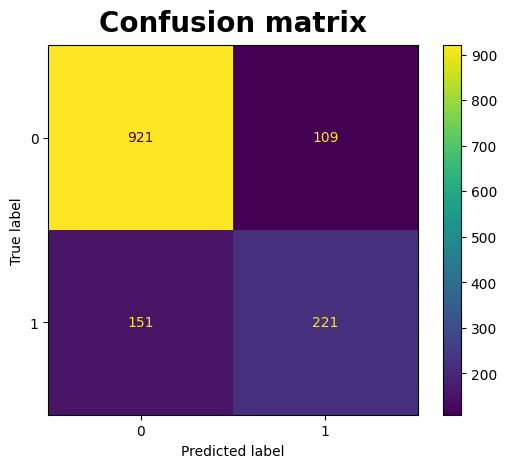

In [139]:
model_training(AdaBoostClassifier_grid.best_estimator_)

- **The best model give same result of initial model, an accuracy 80% and 260 errors on sample of 1402**

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 833><b> CatBoostClassifier() </b></a></h3>

In [142]:
# hyperparameter max_iter, C
param_grid = {'learning_rate' : [0.01, 0.05, 1] ,  'l2_leaf_reg': [ 1, 10], "n_estimators":[None, 50,100], 'loss_function': ['MultiClass', 'Logloss']}
# GridSearchCV
grid_CatBoostClassifier = GridSearchCV(estimator=CatBoostClassifier(verbose = 0, random_state = seed), param_grid = param_grid, scoring = 'f1', cv = 5)
# Train model
CatBoostClassifier_grid = grid_CatBoostClassifier.fit(X_train, y_train)
# best model
print(round(CatBoostClassifier_grid.best_score_, 3))
CatBoostClassifier_grid.best_estimator_

0.584


- **The best for CatBoostClassifier is with default parameters, CatBoostClassifier(verbose = 0, random_state = seed)**

,R2 Score,Adjusted R2 Score,MAE,MSE,RMSE,Training score
0,0.037671,0.016613,0.187589,0.187589,0.433116,0.838088


*****************************************************************
              precision    recall  f1-score      support
0              0.839350  0.902037  0.869565  1031.000000
1              0.656463  0.520216  0.580451   371.000000
accuracy       0.800999  0.800999  0.800999     0.800999
macro avg      0.747906  0.711126  0.725008  1402.000000
weighted avg   0.790954  0.800999  0.793059  1402.000000


<Figure size 1500x500 with 0 Axes>

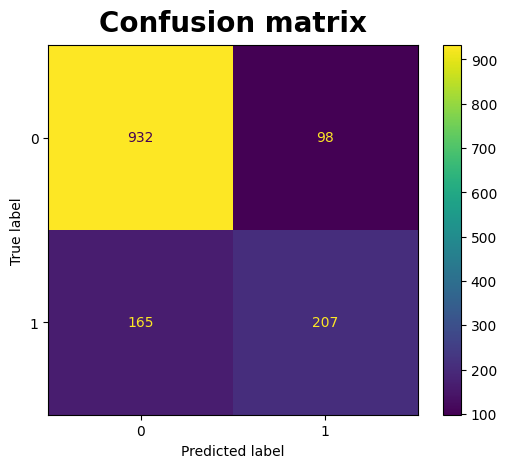

In [144]:
model_training(CatBoostClassifier_grid.best_estimator_)

- **Even with the best settings we did not get better results**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 84><b> Stack model </b></a></h2>

- **Let's try now if we use a stack model to get better results**

In [148]:
stack_model = StackingClassifier(classifiers=(AdaBoostClassifier(learning_rate=1, random_state=seed), CatBoostClassifier(verbose = 0) ),
                                  meta_classifier = LogisticRegression(C=10, random_state = seed),
                                  use_features_in_secondary=True)

,R2 Score,Adjusted R2 Score,MAE,MSE,RMSE,Training score
0,0.044989,0.024092,0.186163,0.186163,0.431466,0.877794


*****************************************************************
              precision    recall  f1-score      support
0              0.838302  0.900097  0.868101  1031.000000
1              0.650847  0.517520  0.576577   371.000000
accuracy       0.798859  0.798859  0.798859     0.798859
macro avg      0.744575  0.708809  0.722339  1402.000000
weighted avg   0.788697  0.798859  0.790957  1402.000000


<Figure size 1500x500 with 0 Axes>

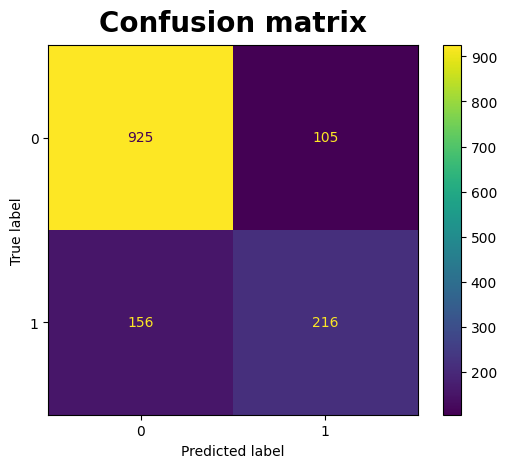

In [149]:
model_training(stack_model)

- **According to these results we see that the stack model does not give advantages, accuracy of around 80% and 261 errors**

- **We choose to continue with AdaBoostClassifier() and LogisticRegression() since they gives the minimum number of errors**  

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 85><b> Importance of predictor features </b></a></h2>

- **Observing the importance of variables in our model, we choose to continue with AdaBoostClassifier(learning_rate=1, random_state=seed) and LogisticRegression(C=10, random_state = seed)**

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 52><b> Features Selection </b></a></h3>

#### <b>AdaBoostClassifier()</b>

Text(0.5, 1.0, 'Importance of predictor features')

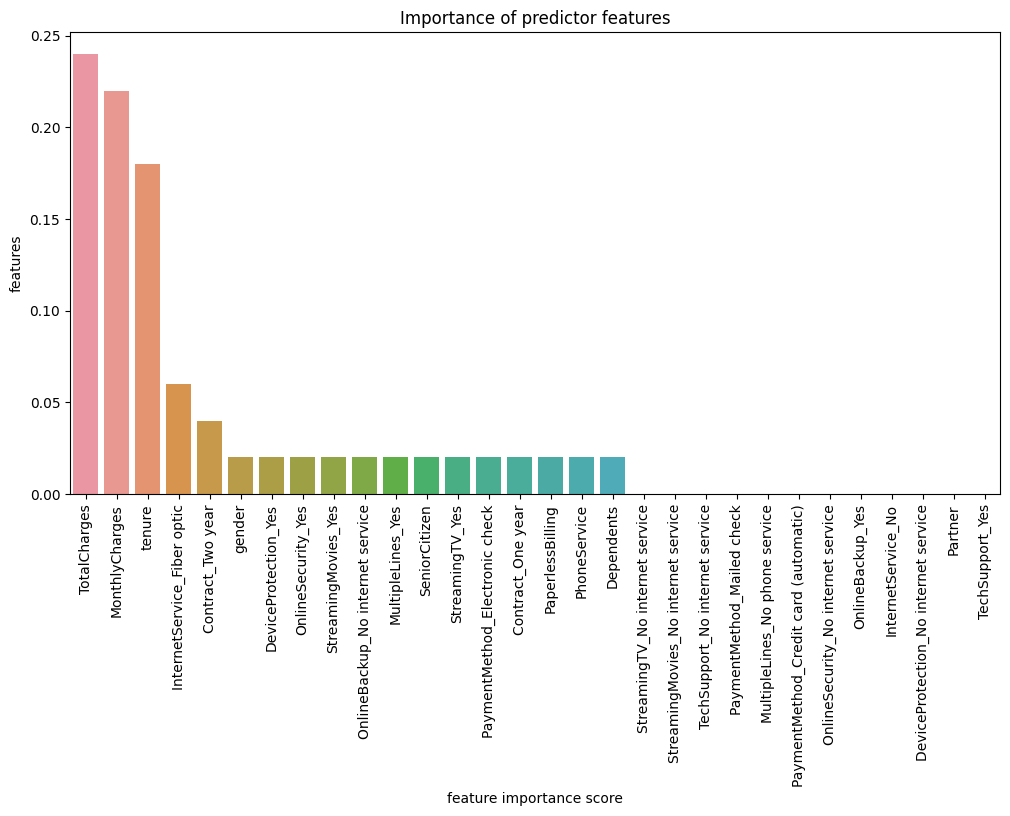

In [156]:
Ada_model = AdaBoostClassifier(learning_rate=1, random_state=seed)
Ada_model.fit(X_train, y_train)
vars_imp  = pd.Series(Ada_model.feature_importances_, index = X_train.columns).sort_values(ascending = False)
plt.figure(figsize=(12, 6))
sns.barplot(x = vars_imp.index, y = vars_imp)
plt.xlabel("feature importance score")
plt.ylabel("features")
plt.xticks(rotation = 90)
plt.title("Importance of predictor features")

In [157]:
X_train.shape

(4206, 30)

- **Let's see if reducing the number of variables will give better results**

In [159]:
# Variables selectionnees pour les Algorithmes
seuil = 0.005
vars_selected = vars_imp[vars_imp>seuil].index.to_list()
Xtrain = X_train[vars_selected]
Xval = X_val[vars_selected]
Xtest = X_test[vars_selected]

In [160]:
Xtrain.shape

(4206, 18)

              precision    recall  f1-score      support
0              0.838329  0.895247  0.865854  1031.000000
1              0.641196  0.520216  0.574405   371.000000
accuracy       0.796006  0.796006  0.796006     0.796006
macro avg      0.739762  0.707731  0.720129  1402.000000
weighted avg   0.786163  0.796006  0.788730  1402.000000


<Figure size 1500x500 with 0 Axes>

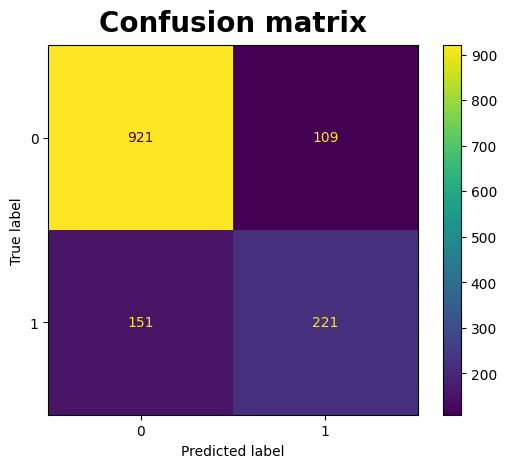

In [161]:
model = Ada_model
model.fit(X_train, y_train)
y_train_pred= model.predict(X_train)
y_test_pred = model.predict(X_test)
  
plt.figure(figsize=(15,5))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion matrix',fontweight="black",size=20,pad=10)
        
report = classification_report(y_val, model.predict(X_val), output_dict=True)
class_report = pd.DataFrame(report).transpose()
print(class_report)

- **We have same result with 18 features, 260 errors**

#### <b> LogisticRegression()</b>

In [164]:
model = LogisticRegression(C=10, random_state = seed)

In [165]:
model.fit(X_train, y_train)
vars_imp = pd.DataFrame(data={
    'Attribute': X_train.columns,
    'Importance': model.coef_[0]
})
vars_imp = vars_imp.sort_values(by='Importance', ascending=False)
vars_imp

,Attribute,Importance
13,InternetService_Fiber optic,0.546554
27,StreamingTV_Yes,0.201513
6,PaperlessBilling,0.188218
16,MultipleLines_Yes,0.185619
22,PaymentMethod_Electronic check,0.129115
1,SeniorCitizen,0.110498
25,StreamingMovies_Yes,0.102011
12,DeviceProtection_Yes,0.074065
15,MultipleLines_No phone service,0.047465
2,Partner,-0.000862


Text(0.5, 1.0, 'Importance of predictor features')

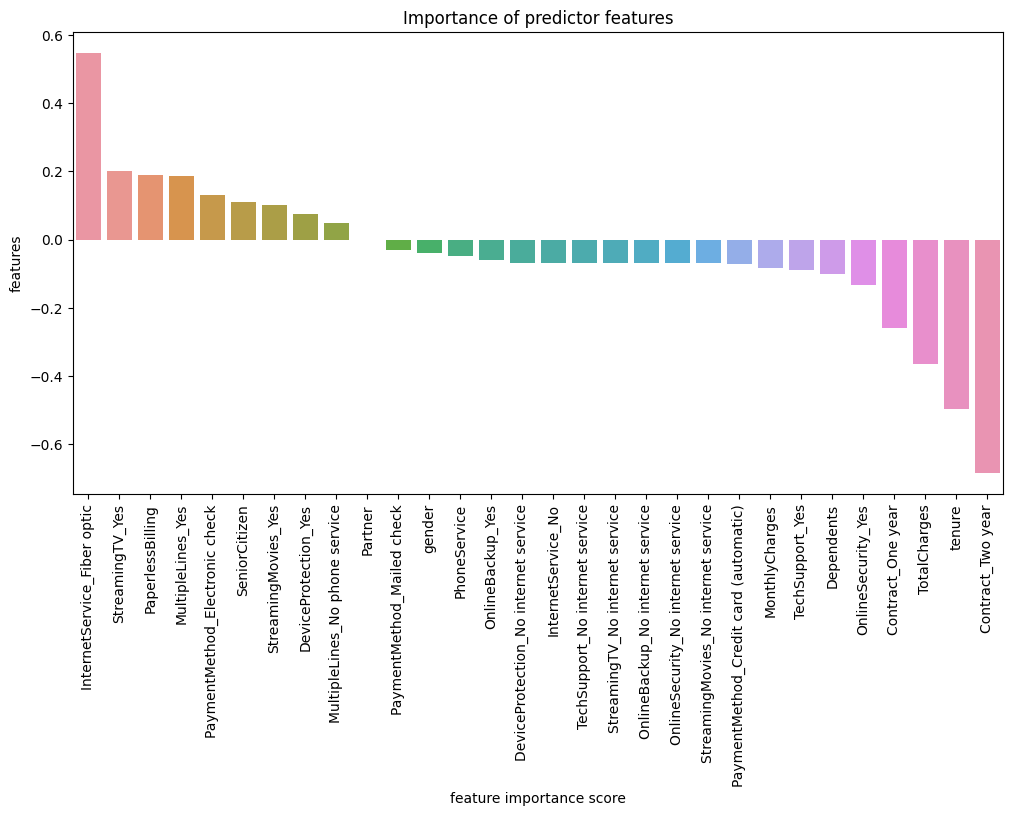

In [166]:
plt.figure(figsize=(12, 6))
sns.barplot(x = vars_imp.Attribute, y = vars_imp.Importance)
plt.xlabel("feature importance score")
plt.ylabel("features")
plt.xticks(rotation = 90)
plt.title("Importance of predictor features")

In [167]:
# selected features
threshold = 0.05  # we try others threshold but more than 0.05 the model give lower accuracy
vars_selected = vars_imp[abs(vars_imp['Importance'])>threshold]['Attribute'].to_list()
vars_selected
Xtrain = X_train[vars_selected]
Xval = X_val[vars_selected]
Xtest = X_test[vars_selected]

In [168]:
Xtrain.shape

(4206, 25)

              precision    recall  f1-score      support
0              0.840970  0.907856  0.873134  1031.000000
1              0.671280  0.522911  0.587879   371.000000
accuracy       0.805991  0.805991  0.805991     0.805991
macro avg      0.756125  0.715384  0.730507  1402.000000
weighted avg   0.796067  0.805991  0.797649  1402.000000


<Figure size 1500x500 with 0 Axes>

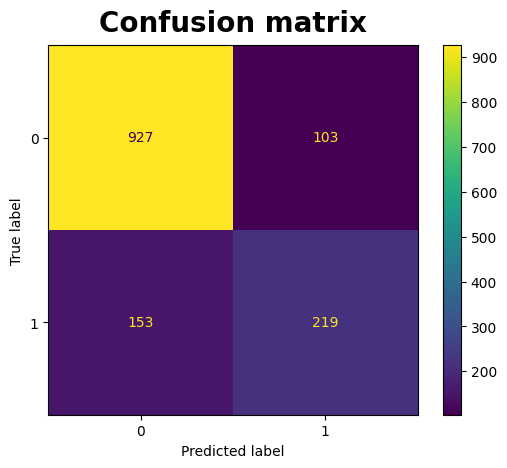

In [169]:
model.fit(Xtrain, y_train)
y_train_pred= model.predict(Xtrain)
y_test_pred = model.predict(Xtest)
  
plt.figure(figsize=(15,5))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion matrix',fontweight="black",size=20,pad=10)
        
report = classification_report(y_val, model.predict(Xval), output_dict=True)
class_report = pd.DataFrame(report).transpose()
print(class_report)

- **If we reduce the number of features even slightly, we obtain a less better result (256 errors) than with the initial number of features (254 errors)**

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 52><b> RFE : Recursive Feature Eliminator </b></a></h3>

- **Let's try to reduce the number of variables with the algorithm RFE Recursive Feature Eliminator**

In [173]:
# function create model using the RFE algorithm
def model_with_rfe(model):
    rfe_model = RFE(estimator = model, verbose = 0)
    rfe_model.fit(X_train, y_train)
    return rfe_model

#### <b> ADABOOSTCLASSIFIER()

In [175]:
Ada_rfe_model = model_with_rfe(Ada_model)
mask = Ada_rfe_model.support_
reduced_X_train = X_train.loc[:, mask]
reduced_X_test = X_test.loc[:, mask]
reduced_X_val = X_val.loc[:, mask]
reduced_X_train.shape

(4206, 15)

              precision    recall  f1-score      support
0              0.831401  0.903977  0.866171  1031.000000
1              0.647687  0.490566  0.558282   371.000000
accuracy       0.794579  0.794579  0.794579     0.794579
macro avg      0.739544  0.697271  0.712227  1402.000000
weighted avg   0.782786  0.794579  0.784697  1402.000000


<Figure size 1500x500 with 0 Axes>

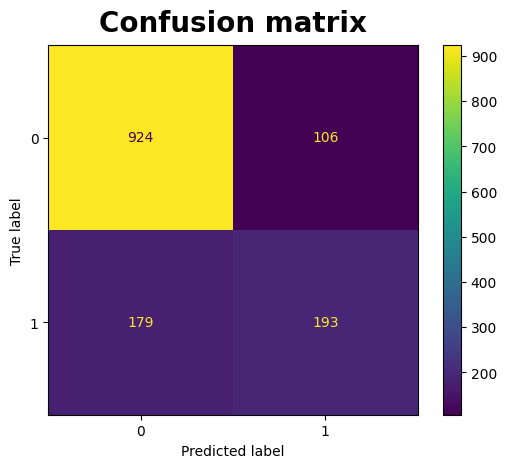

In [176]:
model = Ada_rfe_model
model.fit(reduced_X_train, y_train)
y_train_pred= model.predict(reduced_X_train)
y_test_pred = model.predict(reduced_X_test)
  
plt.figure(figsize=(15,5))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion matrix',fontweight="black",size=20,pad=10)
        
report = classification_report(y_val, model.predict(reduced_X_val), output_dict=True)
class_report = pd.DataFrame(report).transpose()
print(class_report)

#### <b> LogisticRegression()

In [178]:
LR_rfe_model = model_with_rfe(LogisticRegression(C=10, random_state = seed))
mask = LR_rfe_model.support_
reduced_X_train = X_train.loc[:, mask]
reduced_X_test = X_test.loc[:, mask]
reduced_X_val = X_val.loc[:, mask]
reduced_X_train.shape

(4206, 15)

              precision    recall  f1-score    support
0              0.827556  0.903007  0.863636  1031.0000
1              0.638989  0.477089  0.546296   371.0000
accuracy       0.790300  0.790300  0.790300     0.7903
macro avg      0.733272  0.690048  0.704966  1402.0000
weighted avg   0.777657  0.790300  0.779661  1402.0000


<Figure size 1500x500 with 0 Axes>

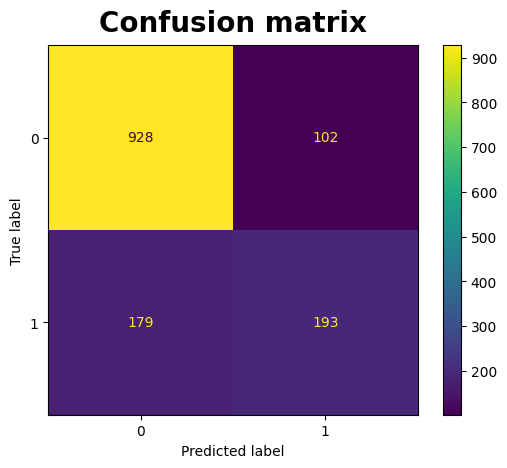

In [179]:
model = LR_rfe_model
model.fit(reduced_X_train, y_train)
y_train_pred= model.predict(reduced_X_train)
y_test_pred = model.predict(reduced_X_test)
  
plt.figure(figsize=(15,5))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion matrix',fontweight="black",size=20,pad=10)
        
report = classification_report(y_val, model.predict(reduced_X_val), output_dict=True)
class_report = pd.DataFrame(report).transpose()
print(class_report)

- **Use RFE algorithm reduce the number of features (15) but did not give a better result**

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 52><b> PCA : Principal component analysis </b></a></h3>

- **What if we use PCA , we can reduce the number of features without loss of significant information**

In [183]:
pca = PCA(n_components = 0.9)
df_del_transformed_pca = pca.fit_transform(df_del_transformed.drop(target, axis = 1))
df_del_transformed_pca = pd.DataFrame(df_del_transformed_pca)
df_del_transformed_pca.head()

,0,1,2,3,4,5,6,7,8,9,10,11
0,4.342817,-1.614800,0.877256,0.153074,0.853176,0.823467,0.490740,-0.645031,0.273795,0.108540,0.940742,0.549660
1,-0.682257,0.179763,0.882039,-0.973113,-0.003992,-0.555955,-0.587913,0.965544,-0.413231,0.011798,-0.441647,-0.115436
2,2.979388,-1.307675,0.878833,-0.176967,-0.283899,-0.529026,-0.589388,0.010774,0.084098,0.918006,0.580940,0.124629
3,-0.920686,0.229865,1.565876,-1.316875,0.347303,-0.402961,0.101004,0.392601,-0.202056,-0.424733,-0.128496,-0.431455
4,2.754809,-1.705420,-0.502992,-0.196054,0.131424,0.569874,-0.182871,-0.266063,-0.010714,-0.004825,-0.059153,-0.323669


In [184]:
# we add target column
df_del_transformed_pca[target] = df_del_transformed[target]
df_del_transformed_pca.head(1)

,0,1,2,3,4,5,6,7,8,9,10,11,Churn
0,4.342817,-1.6148,0.877256,0.153074,0.853176,0.823467,0.49074,-0.645031,0.273795,0.10854,0.940742,0.54966,0


In [185]:
print(df_del_transformed.shape) # 7010*31
df_del_transformed_pca.shape # 7010*13

(7010, 31)


(7010, 13)

In [186]:
# Train dataset (60%), validation dataset (20%) and test dataset (20%)
y, X_train_pca, y_train, X_test_pca, y_test, X_val_pca, y_val = split(df_del_transformed_pca, 0.6)

#### <b>AdaBoostClassifier()</b>

              precision    recall  f1-score      support
0              0.821966  0.900097  0.859259  1031.000000
1              0.622711  0.458221  0.527950   371.000000
accuracy       0.783167  0.783167  0.783167     0.783167
macro avg      0.722338  0.679159  0.693605  1402.000000
weighted avg   0.769239  0.783167  0.771588  1402.000000


<Figure size 1500x500 with 0 Axes>

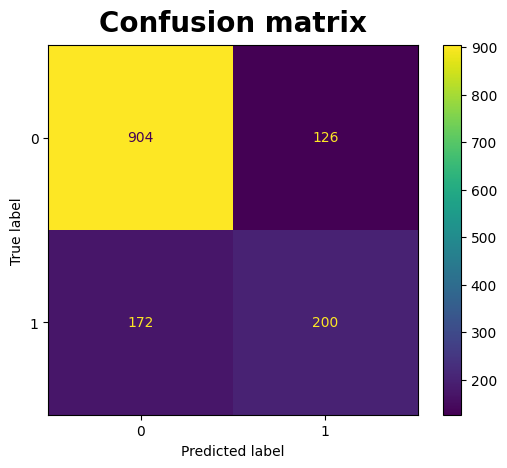

In [188]:
model = Ada_model
model.fit(X_train_pca, y_train)
y_train_pred= model.predict(X_train_pca)
y_test_pred = model.predict(X_test_pca)
  
plt.figure(figsize=(15,5))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion matrix',fontweight="black",size=20,pad=10)
        
report = classification_report(y_val, model.predict(X_val_pca), output_dict=True)
class_report = pd.DataFrame(report).transpose()
print(class_report)

#### <b>LogisticRegression()</b>

              precision    recall  f1-score      support
0              0.832740  0.907856  0.868677  1031.000000
1              0.658273  0.493261  0.563945   371.000000
accuracy       0.798146  0.798146  0.798146     0.798146
macro avg      0.745507  0.700559  0.716311  1402.000000
weighted avg   0.786572  0.798146  0.788038  1402.000000


<Figure size 1500x500 with 0 Axes>

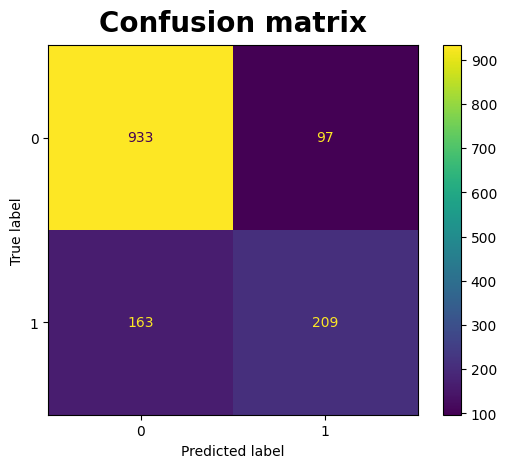

In [190]:
model = LogisticRegression(C=10, random_state = seed)
model.fit(X_train_pca, y_train)
y_train_pred= model.predict(X_train_pca)
y_test_pred = model.predict(X_test_pca)
  
plt.figure(figsize=(15,5))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion matrix',fontweight="black",size=20,pad=10)
        
report = classification_report(y_val, model.predict(X_val_pca), output_dict=True)
class_report = pd.DataFrame(report).transpose()
print(class_report)

- **Use PCA algorithm reduce the number of features (12), it did not give a better result but not bad 260/1402**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 86><b> Artificial Neural Network </b></a></h2>

- **Now what if we try resolve this problem with artificail neural network**

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 861><b> Multi-layer Perceptron classifier</b></a></h3>

,R2 Score,Adjusted R2 Score,MAE,MSE,RMSE,Training score
0,-0.18919,-0.215212,0.231812,0.231812,0.481468,0.893723


*****************************************************************
              precision    recall  f1-score      support
0              0.820327  0.876819  0.847632  1031.000000
1              0.576667  0.466307  0.515648   371.000000
accuracy       0.768188  0.768188  0.768188     0.768188
macro avg      0.698497  0.671563  0.681640  1402.000000
weighted avg   0.755849  0.768188  0.759782  1402.000000


<Figure size 1500x500 with 0 Axes>

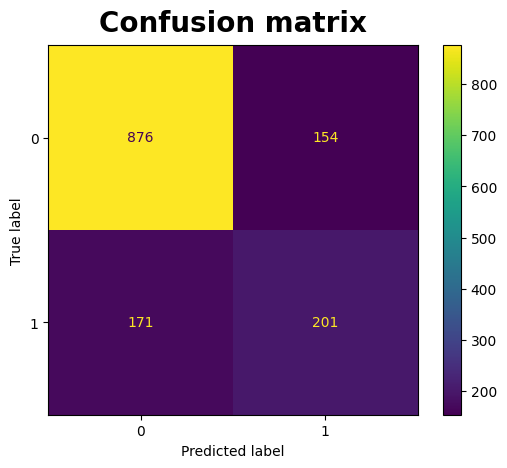

In [195]:
# MLPClassifier 
mlp = MLPClassifier(random_state=seed, max_iter=1000)
model_training(mlp)

- **With this model we have a 305 errors/1402**
- **Lets try to find the best of this model by searching best parameters**

In [197]:
# MLPClassifier with hyperparameters
parametres = {'hidden_layer_sizes':[(10,), (15, ), (20,)], 'activation':['relu', 'tanh', 'logistic', 'identity'], 'learning_rate': ['constant', 'invscaling', 'adaptive']}
mlp_cv = GridSearchCV(mlp, parametres, scoring='f1', cv=5, n_jobs=-1)
mlp_cv.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=MLPClassifier(max_iter=1000, random_state=1234),
             n_jobs=-1,
             param_grid={'activation': ['relu', 'tanh', 'logistic', 'identity'],
                         'hidden_layer_sizes': [(10,), (15,), (20,)],
                         'learning_rate': ['constant', 'invscaling',
                                           'adaptive']},
             scoring='f1')

In [198]:
# best score and best parameters
round(mlp_cv.best_score_, 3)
mlp_cv.best_estimator_

MLPClassifier(activation='identity', hidden_layer_sizes=(10,), max_iter=1000,
              random_state=1234)

,R2 Score,Adjusted R2 Score,MAE,MSE,RMSE,Training score
0,0.074261,0.054005,0.180456,0.180456,0.424802,0.804089


*****************************************************************
              precision    recall  f1-score      support
0              0.837668  0.905917  0.870457  1031.000000
1              0.662021  0.512129  0.577508   371.000000
accuracy       0.801712  0.801712  0.801712     0.801712
macro avg      0.749845  0.709023  0.723982  1402.000000
weighted avg   0.791188  0.801712  0.792936  1402.000000


<Figure size 1500x500 with 0 Axes>

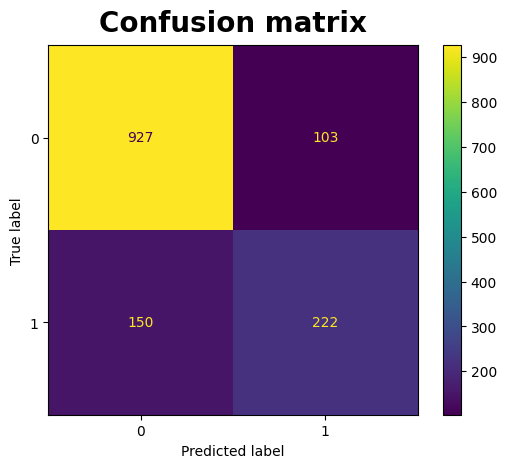

In [199]:
# use the model
model_training(mlp_cv.best_estimator_)

- **The best model is `MLPClassifier(activation='identity', hidden_layer_sizes=(20,), max_iter=1000, random_state=seed)`. We have a best result with `253/1402` errors**

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 862><b> ANN with Keras Tensorflow</b></a></h3>

In [202]:
import tensorflow
from tensorflow import keras

In [203]:
X_train.shape

(4206, 30)

In [204]:
model = keras.Sequential([
    keras.layers.Dense(30, input_shape=(30,), activation='relu'),
    keras.layers.Dense(15, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',loss='binary_crossentropy', metrics=['accuracy'])

In [205]:
model.fit(X_train, y_train, epochs=100)

Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7417 - loss: 0.5065
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7980 - loss: 0.4271
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8123 - loss: 0.4016
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8196 - loss: 0.3883
Epoch 5/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8080 - loss: 0.4106
Epoch 6/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8065 - loss: 0.4094
Epoch 7/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8192 - loss: 0.3901
Epoch 8/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8101 - loss: 0.3974
Epoch 9/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 971us/step - accuracy: 0.8180 - loss: 0.3879
Epoch 10/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8248 - loss: 0.3813
Epoch 11/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 993us/step - accuracy: 0.8073 - loss: 0.3989
Epoch 12/100
132/132 ━━━━━━━━━━━━━━━━

In [206]:
model.evaluate(X_test, y_test)

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7644 - loss: 0.5402  


[0.5563661456108093, 0.7596291303634644]

In [207]:
y_train_pred = model.predict(X_train)

132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [208]:
y_train_pred = y_train_pred.round()
y_train_pred

array([[1.],
       [1.],
       [0.],
       ...,
       [0.],
       [0.],
       [0.]], dtype=float32)

In [209]:
y_test_pred = model.predict(X_test)
y_test_pred = y_test_pred.round()
y_test_pred

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[0.],
       [0.],
       [0.],
       ...,
       [0.],
       [0.],
       [1.]], dtype=float32)

Text(0.5, 1.0, 'Confusion matrix')

<Figure size 1500x500 with 0 Axes>

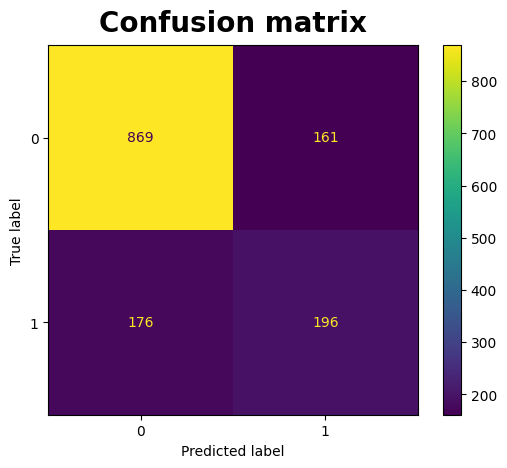

In [210]:
plt.figure(figsize=(15,5))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion matrix',fontweight="black",size=20,pad=10)

- **We have not a better result**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 87><b> H2O AUTO ML </b></a></h2>

- **Let try to use one tool that automatically runs through all the algorithms and their hyperparameters to produce a leaderboard of the best models, its `H2O Auto ML`**

In [214]:
import h2o
from h2o.automl import H2OAutoML

In [215]:
h2o.init()

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; Java HotSpot(TM) Client VM (build 25.401-b10, mixed mode, sharing)
  Starting server from C:\Users\pc15\anaconda3\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\pc15\AppData\Local\Temp\tmpvpmie_xe
  JVM stdout: C:\Users\pc15\AppData\Local\Temp\tmpvpmie_xe\h2o_pc15_started_from_python.out
  JVM stderr: C:\Users\pc15\AppData\Local\Temp\tmpvpmie_xe\h2o_pc15_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,02 secs
H2O_cluster_timezone:,Asia/Muscat
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.1
H2O_cluster_version_age:,2 months and 24 days
H2O_cluster_name:,H2O_from_python_pc15_8khv8r
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,247.5 Mb
H2O_cluster_total_cores:,0
H2O_cluster_allowed_cores:,0
H2O_cluster_status:,"locked, healthy"


In [216]:
df_h2o = df_del.copy()
df_h2o.head(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [217]:
# Transform dataframe pandas to H2O frame
h2o_df = h2o.H2OFrame(df_h2o)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [218]:
h2o_df.describe()

Rows:7010
Cols:20

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
type,enum,int,enum,enum,int,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,enum,real,real,enum
mins,,0.0,,,1.0,,,,,,,,,,,,,18.25,18.8,
mean,,0.16276747503566333,,,32.520399429386586,,,,,,,,,,,,,64.88866619115568,2290.3533880171253,
maxs,,1.0,,,72.0,,,,,,,,,,,,,118.75,8684.8,
sigma,,0.369179721618969,,,24.52044136889312,,,,,,,,,,,,,30.064768676947466,2266.8208317475573,
zeros,,5869,,,0,,,,,,,,,,,,,0,0,
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,Female,0.0,Yes,No,1.0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0.0,No,No,34.0,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0.0,No,No,2.0,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [219]:
train, test = h2o_df.split_frame(ratios = [0.75])
x = train.columns
y = 'Churn'
x.remove(y)

In [220]:
df_del[y].value_counts(normalize = True)

Churn
No     0.735093
Yes    0.264907
Name: proportion, dtype: float64

In [221]:
# Create H2OAutoML model
aml = H2OAutoML(max_runtime_secs = 600, 
                balance_classes = True, 
                stopping_metric = 'logloss',
                project_name ='Final', 
                seed = 1)

# train model
%time aml.train(x = x, y = y, training_frame = train)

AutoML progress: |
01:39:09.714: AutoML: XGBoost is not available; skipping it.

███████████████████████████████████████████████████████████████| (done) 100%
CPU times: total: 469 ms
Wall time: 25min 57s


Model Details
=============
H2OStackedEnsembleEstimator : Stacked Ensemble
Model Key: StackedEnsemble_BestOfFamily_1_AutoML_1_20240607_13909


Model Summary for Stacked Ensemble: 
key                                   value
------------------------------------  ----------------
Stacking strategy                     cross_validation
Number of base models (used / total)  2/2
# GBM base models (used / total)      1/1
# GLM base models (used / total)      1/1
Metalearner algorithm                 GLM
Metalearner fold assignment scheme    Random
Metalearner nfolds                    5
Metalearner fold_column
Custom metalearner hyperparameters    None

ModelMetricsBinomialGLM: stackedensemble
** Reported on train data. **

MSE: 0.12289951213640922
RMSE: 0.3505702670455799
LogLoss: 0.3808964417732141
AUC: 0.8739393115142498
AUCPR: 0.7132860085893747
Gini: 0.7478786230284995
Null degrees of freedom: 5228
Residual degrees of freedom: 5226
Null deviance: 6008.579839213129
Residual deviance: 3983.414988064272
AIC: 3989.414988064272

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.3134702852159996
       No    Yes    Error    Rate
-----  ----  -----  -------  ---------------
No     3072  790    0.2046   (790.0/3862.0)
Yes    302   1065   0.2209   (302.0/1367.0)
Total  3374  1855   0.2088   (1092.0/5229.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.31347      0.66108   215
max f2                       0.185101     0.768896  278
max f0point5                 0.56122      0.677222  109
max accuracy                 0.486048     0.824441  140
max precision                0.861954     1         0
max recall                   0.0112528    1         389
max specificity              0.861954     1         0
max absolute_mcc             0.435584     0.529029  162
max min_per_class_accuracy   0.306104     0.785662  219
max mean_per_class_accuracy  0.277951     0.790485  233
max tns                      0.861954     3862      0
max fns                      0.861954     1364      0
max fps                      0.00344959   3862      399
max tps                      0.0112528    1367      389
max tnr                      0.861954     1         0
max fnr                      0.861954     0.997805  0
max fpr                      0.00344959   1         399
max tpr                      0.0112528    1         389

Gains/Lift Table: Avg response rate: 26.14 %, avg score: 26.14 %
group    cumulative_data_fraction    lower_threshold    lift       cumulative_lift    response_rate    score       cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  ---------  -----------------  ---------------  ----------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.0101358                   0.811967           3.53647    3.53647            0.924528         0.831266    0.924528                    0.831266            0.0358449       0.0358449                  253.647   253.647            0.0348092
2        0.0200803                   0.788308           3.53092    3.53372            0.923077         0.800402    0.92381                     0.815981            0.0351134       0.0709583                  253.092   253.372            0.0688868
3        0.0300249                   0.768284           3.45736    3.50843            0.903846         0.778327    0.917197                    0.80351             0.0343819       0.10534                    245.736   250.843            0.101974
4        0.0401606                   0.754057           3.39213    3.47908            0.886792         0.760536    0.909524                    0.792664            0.0343819       0.139722      

In [222]:
# Leaderboard
lb = aml.leaderboard
lb.head(rows = lb.nrows) # All rows

model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse
StackedEnsemble_BestOfFamily_1_AutoML_1_20240607_13909,0.849112,0.409215,0.653646,0.232607,0.365025,0.133243
GLM_1_AutoML_1_20240607_13909,0.847714,0.411654,0.648379,0.231525,0.366009,0.133963
GBM_1_AutoML_1_20240607_13909,0.844881,0.414033,0.65182,0.232412,0.367154,0.134802
GBM_2_AutoML_1_20240607_13909,0.836479,0.427174,0.638422,0.241815,0.37201,0.138391
GBM_3_AutoML_1_20240607_13909,0.83421,0.431535,0.627798,0.241132,0.374147,0.139986
DRF_1_AutoML_1_20240607_13909,0.82352,0.493761,0.604915,0.251033,0.38663,0.149482


In [223]:
# Show all columns of leaderboard
lb = h2o.automl.get_leaderboard(aml, extra_columns = 'ALL')
lb

model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse,training_time_ms,predict_time_per_row_ms,algo
StackedEnsemble_BestOfFamily_1_AutoML_1_20240607_13909,0.849112,0.409215,0.653646,0.232607,0.365025,0.133243,379,0.094341,StackedEnsemble
GLM_1_AutoML_1_20240607_13909,0.847714,0.411654,0.648379,0.231525,0.366009,0.133963,101,0.006075,GLM
GBM_1_AutoML_1_20240607_13909,0.844881,0.414033,0.65182,0.232412,0.367154,0.134802,300,0.028778,GBM
GBM_2_AutoML_1_20240607_13909,0.836479,0.427174,0.638422,0.241815,0.37201,0.138391,395,0.022226,GBM
GBM_3_AutoML_1_20240607_13909,0.83421,0.431535,0.627798,0.241132,0.374147,0.139986,199744,0.006824,GBM
DRF_1_AutoML_1_20240607_13909,0.82352,0.493761,0.604915,0.251033,0.38663,0.149482,1925,0.100809,DRF


In [224]:
# best model
model = aml.leader
model

Model Details
=============
H2OStackedEnsembleEstimator : Stacked Ensemble
Model Key: StackedEnsemble_BestOfFamily_1_AutoML_1_20240607_13909


Model Summary for Stacked Ensemble: 
key                                   value
------------------------------------  ----------------
Stacking strategy                     cross_validation
Number of base models (used / total)  2/2
# GBM base models (used / total)      1/1
# GLM base models (used / total)      1/1
Metalearner algorithm                 GLM
Metalearner fold assignment scheme    Random
Metalearner nfolds                    5
Metalearner fold_column
Custom metalearner hyperparameters    None

ModelMetricsBinomialGLM: stackedensemble
** Reported on train data. **

MSE: 0.12289951213640922
RMSE: 0.3505702670455799
LogLoss: 0.3808964417732141
AUC: 0.8739393115142498
AUCPR: 0.7132860085893747
Gini: 0.7478786230284995
Null degrees of freedom: 5228
Residual degrees of freedom: 5226
Null deviance: 6008.579839213129
Residual deviance: 3983.414988064272
AIC: 3989.414988064272

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.3134702852159996
       No    Yes    Error    Rate
-----  ----  -----  -------  ---------------
No     3072  790    0.2046   (790.0/3862.0)
Yes    302   1065   0.2209   (302.0/1367.0)
Total  3374  1855   0.2088   (1092.0/5229.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.31347      0.66108   215
max f2                       0.185101     0.768896  278
max f0point5                 0.56122      0.677222  109
max accuracy                 0.486048     0.824441  140
max precision                0.861954     1         0
max recall                   0.0112528    1         389
max specificity              0.861954     1         0
max absolute_mcc             0.435584     0.529029  162
max min_per_class_accuracy   0.306104     0.785662  219
max mean_per_class_accuracy  0.277951     0.790485  233
max tns                      0.861954     3862      0
max fns                      0.861954     1364      0
max fps                      0.00344959   3862      399
max tps                      0.0112528    1367      389
max tnr                      0.861954     1         0
max fnr                      0.861954     0.997805  0
max fpr                      0.00344959   1         399
max tpr                      0.0112528    1         389

Gains/Lift Table: Avg response rate: 26.14 %, avg score: 26.14 %
group    cumulative_data_fraction    lower_threshold    lift       cumulative_lift    response_rate    score       cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  ---------  -----------------  ---------------  ----------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.0101358                   0.811967           3.53647    3.53647            0.924528         0.831266    0.924528                    0.831266            0.0358449       0.0358449                  253.647   253.647            0.0348092
2        0.0200803                   0.788308           3.53092    3.53372            0.923077         0.800402    0.92381                     0.815981            0.0351134       0.0709583                  253.092   253.372            0.0688868
3        0.0300249                   0.768284           3.45736    3.50843            0.903846         0.778327    0.917197                    0.80351             0.0343819       0.10534                    245.736   250.843            0.101974
4        0.0401606                   0.754057           3.39213    3.47908            0.886792         0.760536    0.909524                    0.792664            0.0343819       0.139722      

In [225]:
# Performance of best model with data test
model.model_performance(test)

ModelMetricsBinomialGLM: stackedensemble
** Reported on test data. **

MSE: 0.13985293009638566
RMSE: 0.3739691566110575
LogLoss: 0.4315712490993383
AUC: 0.8390007745933385
AUCPR: 0.6551281542803475
Gini: 0.6780015491866771
Null degrees of freedom: 1780
Residual degrees of freedom: 1778
Null deviance: 2097.2055049523974
Residual deviance: 1537.256789291843
AIC: 1543.256789291843

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.29162502057886014
       No    Yes    Error    Rate
-----  ----  -----  -------  --------------
No     982   309    0.2393   (309.0/1291.0)
Yes    110   380    0.2245   (110.0/490.0)
Total  1092  689    0.2353   (419.0/1781.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.291625     0.644614  220
max f2                       0.145517     0.754049  297
max f0point5                 0.472575     0.645311  140
max accuracy                 0.472575     0.803481  140
max precision                0.864411     1         0
max recall                   0.00567093   1         396
max specificity              0.864411     1         0
max absolute_mcc             0.291625     0.491627  220
max min_per_class_accuracy   0.298682     0.765306  216
max mean_per_class_accuracy  0.277165     0.76966   228
max tns                      0.864411     1291      0
max fns                      0.864411     488       0
max fps                      0.00347219   1291      399
max tps                      0.00567093   490       396
max tnr                      0.864411     1         0
max fnr                      0.864411     0.995918  0
max fpr                      0.00347219   1         399
max tpr                      0.00567093   1         396

Gains/Lift Table: Avg response rate: 27.51 %, avg score: 26.38 %
group    cumulative_data_fraction    lower_threshold    lift       cumulative_lift    response_rate    score       cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  ---------  -----------------  ---------------  ----------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.0101067                   0.804952           2.82698    2.82698            0.777778         0.833424    0.777778                    0.833424            0.0285714       0.0285714                  182.698   182.698            0.0254731
2        0.0202134                   0.782283           3.63469    3.23084            1                0.792053    0.888889                    0.812738            0.0367347       0.0653061                  263.469   223.084            0.0622077
3        0.03032                     0.760006           2.82698    3.09622            0.777778         0.774484    0.851852                    0.799987            0.0285714       0.0938776                  182.698   209.622            0.0876808
4        0.0404267                   0.749561           3.02891    3.07939            0.833333         0.754607    0.847222                    0.788642            0.0306122       0.12449                    202.891   207.939            0.115969
5        0.0505334                   0.736918           2.62506    2.98853            0.722222         0.742165    0.822222                    0.779347            0.0265306       0.15102                    162.506   198.853            0.138627
6        0.100505                    0.65579            2.36868    2.68033            0.651685         0.695643    0.73743                     0.737728            0.118367        0.269388                   136.868   168.033            0.232982
7        0.150477                    0.577295           2.36868    2.57684            0.651685         0.61629     0.

- **The best model found by h2o is a stack model with an error percentage equal to 23.61%, it is less efficient than AdaBoosterClassifier() and LogesticRegression()**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 88><b> PYCARET </b></a></h2>

- **Let's try a tool that that automates machine learning workflows in order to find the best solution, this tool is PYCARET**

In [229]:
from sklearn.metrics._scorer import _SCORERS
from pycaret.classification import *

In [230]:
# Setup initialisation
Pycaret_exp = setup(data = df_del,  target = target)

,Description,Value
0,Session id,3187
1,Target,Churn
2,Target type,Binary
3,Target mapping,"No: 0, Yes: 1"
4,Original data shape,"(7010, 20)"
5,Transformed data shape,"(7010, 41)"
6,Transformed train set shape,"(4907, 41)"
7,Transformed test set shape,"(2103, 41)"
8,Numeric features,4
9,Categorical features,15


- **We can choose one model, We try LogisticRegression() and AdatBoostClassifier() models**

### <b> AdatBoostClassifier() </b>

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7902,0.0000,0.7902,0.7771,0.7788,0.4104,0.4189
1,0.8289,0.0000,0.8289,0.8213,0.8192,0.5179,0.5293
2,0.7882,0.0000,0.7882,0.7742,0.7754,0.3998,0.4098
3,0.8289,0.0000,0.8289,0.8219,0.8230,0.5330,0.5378
4,0.7841,0.0000,0.7841,0.7765,0.7794,0.4228,0.4244
5,0.7800,0.0000,0.7800,0.7676,0.7709,0.3932,0.3982
6,0.8126,0.0000,0.8126,0.8064,0.8085,0.4990,0.5009
7,0.8041,0.0000,0.8041,0.7962,0.7986,0.4715,0.4743
8,0.7878,0.0000,0.7878,0.7781,0.7811,0.4244,0.4276


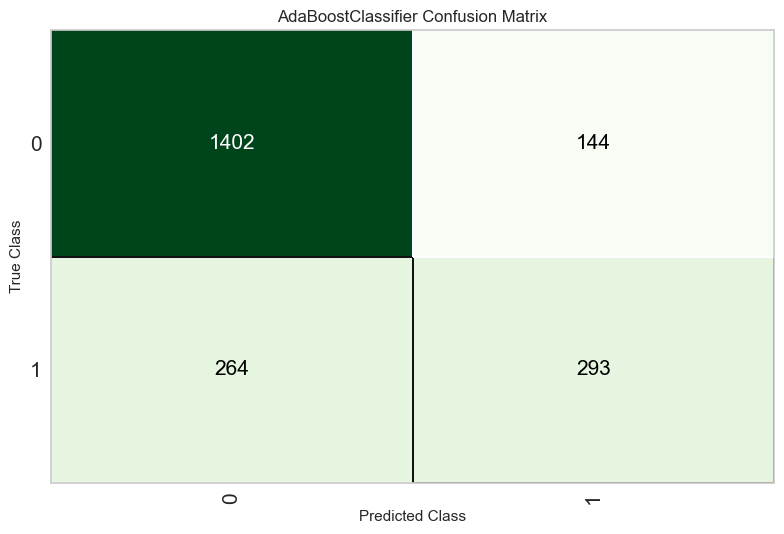

In [233]:
ADA_model = create_model('ada') 
plot_model(ADA_model, plot = 'confusion_matrix')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7963,0.0000,0.7963,0.7831,0.7814,0.4134,0.4279
1,0.8167,0.0000,0.8167,0.8091,0.7999,0.4601,0.4843
2,0.8086,0.0000,0.8086,0.7992,0.7901,0.4329,0.4579
3,0.8126,0.0000,0.8126,0.8045,0.7946,0.4450,0.4706
4,0.7923,0.0000,0.7923,0.7781,0.7733,0.3881,0.4085
5,0.7780,0.0000,0.7780,0.7617,0.7632,0.3658,0.3767
6,0.8024,0.0000,0.8024,0.7911,0.7916,0.4447,0.4539
7,0.8163,0.0000,0.8163,0.8076,0.8087,0.4940,0.5003
8,0.7959,0.0000,0.7959,0.7847,0.7867,0.4348,0.4412


Fitting 10 folds for each of 10 candidates, totalling 100 fits


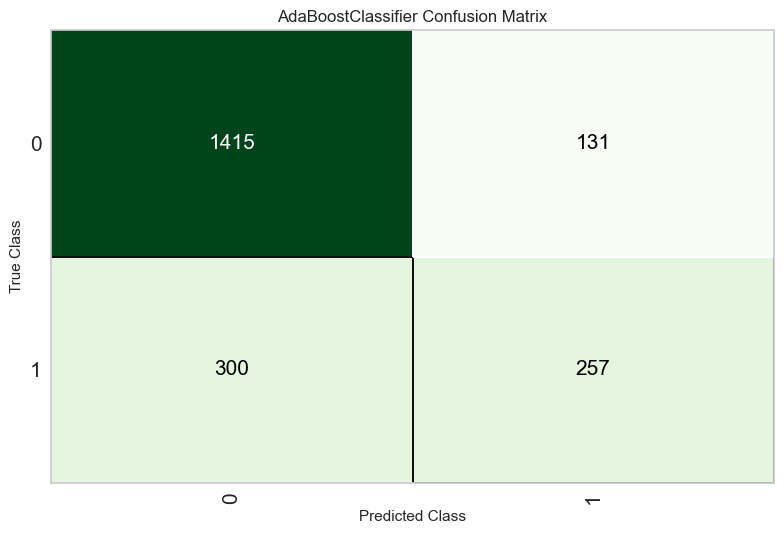

In [234]:
# Tunning model
ADA_best = tune_model(ADA_model)
plot_model(ADA_best, plot = 'confusion_matrix')

### <b> LogisticRegression() </b>

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8024,0.0000,0.8024,0.7936,0.7959,0.4621,0.4659
1,0.8208,0.0000,0.8208,0.8131,0.8145,0.5108,0.5154
2,0.8024,0.0000,0.8024,0.7914,0.7924,0.4477,0.4558
3,0.7963,0.0000,0.7963,0.7886,0.7912,0.4526,0.4548
4,0.7821,0.0000,0.7821,0.7740,0.7770,0.4158,0.4176
5,0.7963,0.0000,0.7963,0.7873,0.7899,0.4469,0.4503
6,0.8045,0.0000,0.8045,0.7960,0.7983,0.4691,0.4726
7,0.8184,0.0000,0.8184,0.8117,0.8135,0.5113,0.5141
8,0.7980,0.0000,0.7980,0.7907,0.7932,0.4591,0.4611


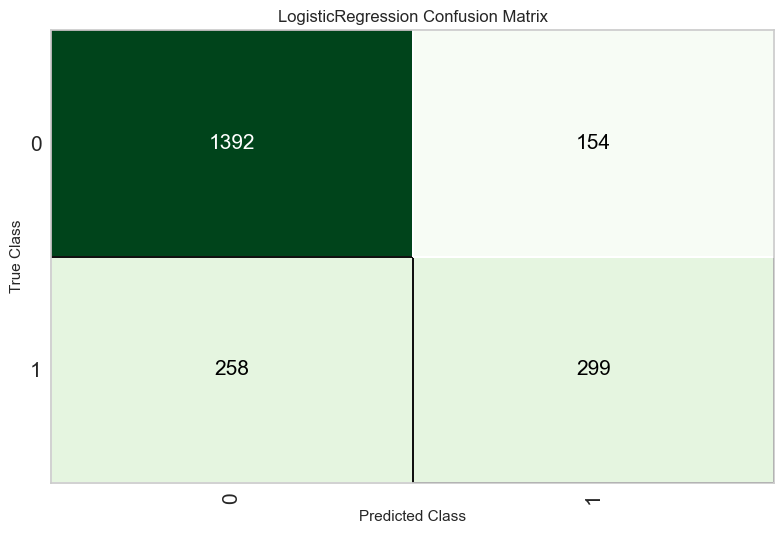

In [236]:
LR_model = create_model('lr') 
plot_model(LR_model, plot = 'confusion_matrix')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8024,0.0000,0.8024,0.7936,0.7959,0.4621,0.4659
1,0.8208,0.0000,0.8208,0.8131,0.8145,0.5108,0.5154
2,0.8065,0.0000,0.8065,0.7960,0.7967,0.4591,0.4674
3,0.7943,0.0000,0.7943,0.7861,0.7888,0.4457,0.4482
4,0.7821,0.0000,0.7821,0.7740,0.7770,0.4158,0.4176
5,0.7963,0.0000,0.7963,0.7873,0.7899,0.4469,0.4503
6,0.8065,0.0000,0.8065,0.7980,0.8001,0.4732,0.4771
7,0.8184,0.0000,0.8184,0.8117,0.8135,0.5113,0.5141
8,0.7959,0.0000,0.7959,0.7889,0.7914,0.4551,0.4568


Fitting 10 folds for each of 10 candidates, totalling 100 fits


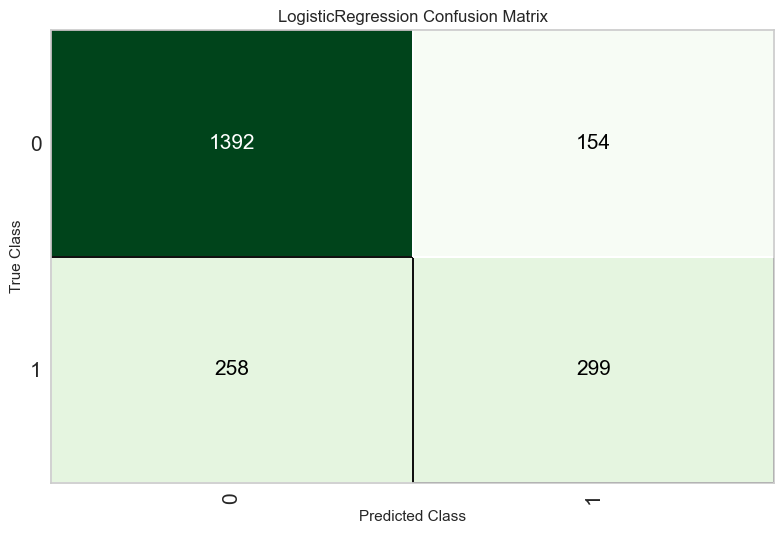

In [237]:
# Tunning model
LR_best = tune_model(LR_model)
plot_model(LR_best, plot = 'confusion_matrix')

### <b>Train models and select the best </b>

In [239]:
best = compare_models(sort='F1')
best

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lr,Logistic Regression,0.8033,0.0000,0.8033,0.7952,0.7974,0.4674,0.4708,0.2010
ridge,Ridge Classifier,0.8009,0.0000,0.8009,0.7909,0.7926,0.4510,0.4571,0.0760
gbc,Gradient Boosting Classifier,0.8009,0.0000,0.8009,0.7908,0.7924,0.4505,0.4567,0.1940
ada,Ada Boost Classifier,0.8001,0.0000,0.8001,0.7904,0.7921,0.4507,0.4562,0.1550
lda,Linear Discriminant Analysis,0.7954,0.0000,0.7954,0.7886,0.7908,0.4530,0.4550,0.0710
catboost,CatBoost Classifier,0.7995,0.0000,0.7995,0.7891,0.7908,0.4460,0.4522,3.3690
lightgbm,Light Gradient Boosting Machine,0.7948,0.0000,0.7948,0.7849,0.7873,0.4387,0.4431,0.3670
xgboost,Extreme Gradient Boosting,0.7856,0.0000,0.7856,0.7770,0.7796,0.4216,0.4245,0.1090
rf,Random Forest Classifier,0.7879,0.0000,0.7879,0.7753,0.7775,0.4090,0.4159,0.1620
knn,K Neighbors Classifier,0.7610,0.0000,0.7610,0.7470,0.7507,0.3402,0.3452,0.0950


LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=1000,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=3187, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False)

In [240]:
# Reglages des hyperparametres
tuned_best = tune_model(best)
tuned_best

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8024,0.0000,0.8024,0.7936,0.7959,0.4621,0.4659
1,0.8208,0.0000,0.8208,0.8131,0.8145,0.5108,0.5154
2,0.8065,0.0000,0.8065,0.7960,0.7967,0.4591,0.4674
3,0.7943,0.0000,0.7943,0.7861,0.7888,0.4457,0.4482
4,0.7821,0.0000,0.7821,0.7740,0.7770,0.4158,0.4176
5,0.7963,0.0000,0.7963,0.7873,0.7899,0.4469,0.4503
6,0.8065,0.0000,0.8065,0.7980,0.8001,0.4732,0.4771
7,0.8184,0.0000,0.8184,0.8117,0.8135,0.5113,0.5141
8,0.7959,0.0000,0.7959,0.7889,0.7914,0.4551,0.4568


Fitting 10 folds for each of 10 candidates, totalling 100 fits


LogisticRegression(C=3.321, class_weight={}, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=1000,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=3187, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False)

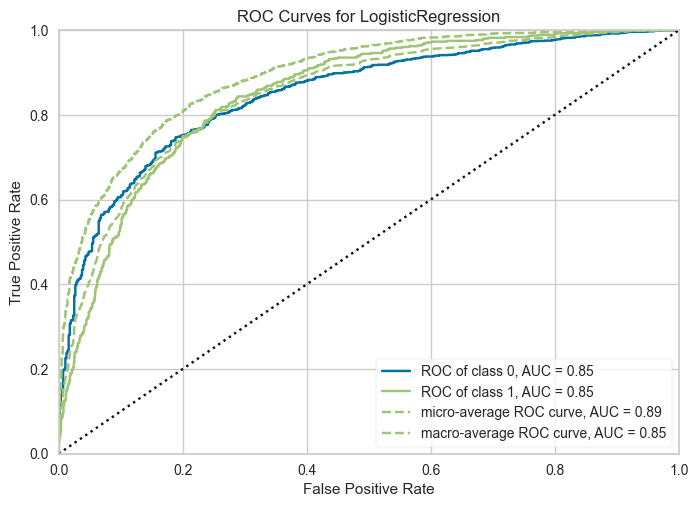

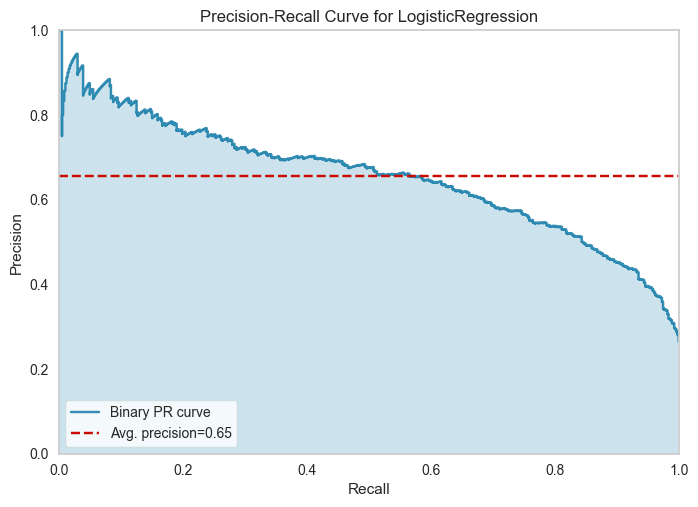

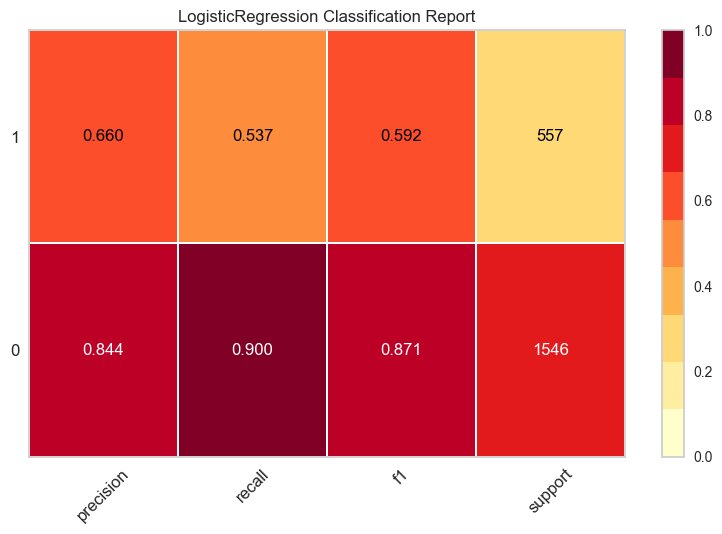

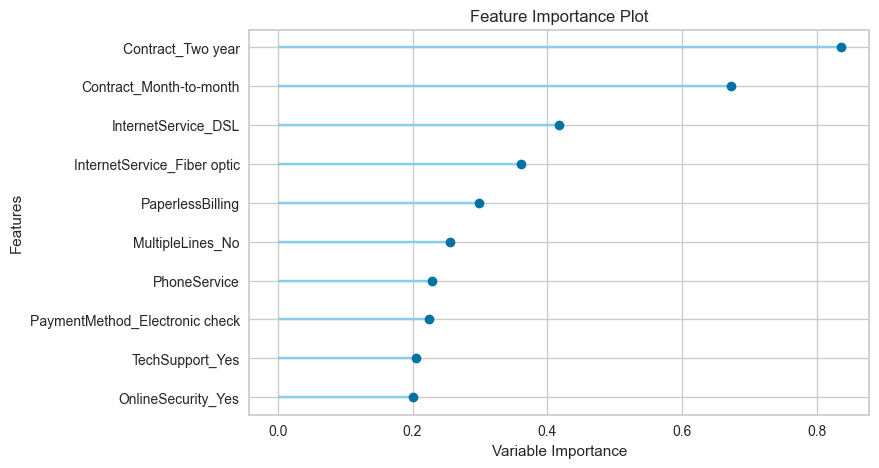

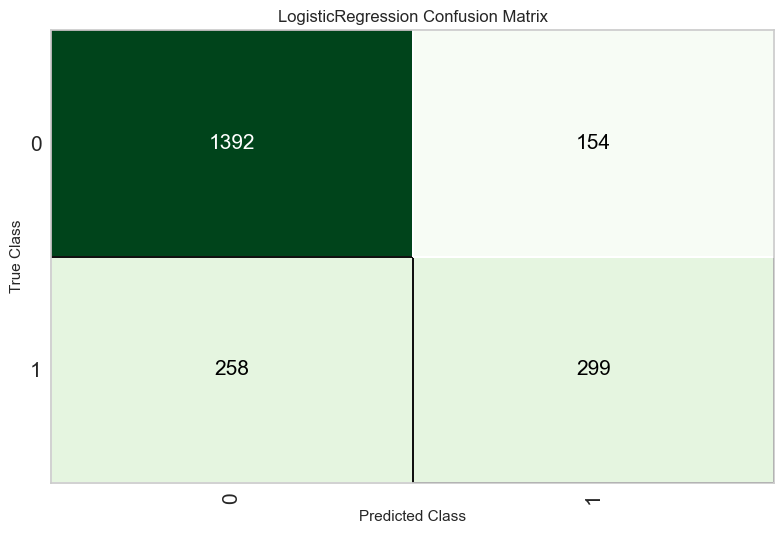

In [241]:
# model Analyse
# AUC
plot_model(tuned_best, plot = 'auc') 
# precision -recall
plot_model(tuned_best, plot = 'pr')
# Classification Report
plot_model(tuned_best, plot = 'class_report')
# features importance
plot_model(tuned_best, plot = 'feature')
# confusion matrix
plot_model(tuned_best, plot = 'confusion_matrix')

- **We have an accuracy of around 78.4% with 454 errors on sample of 2103, 21.6%**

In [243]:
final_best = finalize_model(best)
final_best

Pipeline(memory=Memory(location=None),
         steps=[('label_encoding',
                 TransformerWrapperWithInverse(exclude=None, include=None,
                                               transformer=LabelEncoder())),
                ('numerical_imputer',
                 TransformerWrapper(exclude=None,
                                    include=['SeniorCitizen', 'tenure',
                                             'MonthlyCharges', 'TotalCharges'],
                                    transformer=SimpleImputer(add_indicator=False,
                                                              copy=True,
                                                              fill_value=None,
                                                              keep_empty...
                                                              handle_missing='return_nan',
                                                              handle_unknown='value',
                                                              return_df=True,
                                                              use_cat_names=True,
                                                              verbose=0))),
                ('actual_estimator',
                 LogisticRegression(C=1.0, class_weight=None, dual=False,
                                    fit_intercept=True, intercept_scaling=1,
                                    l1_ratio=None, max_iter=1000,
                                    multi_class='auto', n_jobs=None,
                                    penalty='l2', random_state=3187,
                                    solver='lbfgs', tol=0.0001, verbose=0,
                                    warm_start=False))],
         verbose=False)

In [244]:
# save pipeline
pipeline_CustomerChurn = save_model(final_best, 'Pipeline_Customer_Churn')
pipeline_CustomerChurn

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('label_encoding',
                  TransformerWrapperWithInverse(exclude=None, include=None,
                                                transformer=LabelEncoder())),
                 ('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['SeniorCitizen', 'tenure',
                                              'MonthlyCharges', 'TotalCharges'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empty...
                                                               handle_missing='return_nan',
                                                               handle_unknown='value',
                                

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 9><b> PIPELINE</b></a></h1>

- **We are going to change the strategy, we want to use pipelines to carry out several experiments, so we are going to replace the functions and processing carried out previously by classes, then we are going to define a pipeline for each experiment**

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 91><b> Class </b></a></h2>

In [248]:
class drop_id():
    def __init__(self, col):
        self.col = col
    def fit(self, df, y=None):
        return self
    
    def transform(self,df, y = None):
        df = df.drop(self.col, axis=1)
        return df

In [249]:
class deal_totalcharges() :
    def fit(self, df, y=None):
        return self
    def transform(self,df, y = None):
        df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)
        df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])
        return df

In [250]:
class drop_duplicate():
    def fit(self, df, y=None):
        return self
    def transform(self,df, y = None):
        df = df[df.duplicated()== False]
        return df

In [251]:
def fill_by_median (df, feature1, feature2):
        feat1 = df_mean[feature1].unique()
        feat2 = df_mean[feature2].unique()
        mean_totalcharges = np.zeros((len(feat1),len(feat2)))
    
        for f1 in feat1 :
            i = np.where(feat1 == f1)[0][0]
            for f2 in feat2:
                j = np.where(feat2 == f2)[0][0]
                mean_df = df_mean[(df[feature1] == f1) & (df[feature2] == f2)]['TotalCharges'].dropna().median() 
                mean_totalcharges[i, j]=mean_df
   
        for i in range(0, len(feat1)):
            f1 = feat1[i]
            for j in range(0, len(feat2)):
                f2 = feat2[j]
                if not(df.loc[df_mean['TotalCharges'].isnull() & (df[feature1]==f1) & (df[feature2] == f2)].empty):
                    df.loc[df['TotalCharges'].isnull() & (df[feature1]==f1) & (df[feature2] == f2), 'TotalCharges'] = mean_totalcharges[i,j]
        return df

In [252]:
class imputer() :
    def __init__(self, strategy):
        self.strategy = strategy
    def fit(self, df, y=None):
        return self
    
    def transform(self,df, y = None):
        if self.strategy == 'drop' :
            df.dropna(inplace = True)
        if self.strategy == 'median' :
            feature1 = 'Contract'
            feature2 = 'OnlineSecurity'
            df = fill_by_median (df, feature1, feature2)
        return df

In [253]:
class transform_data():
    def __init__(self, transformer):
        self.transformer = transformer
    def fit(self, df, y=None):
        return self
    
    def transform(self,df, y = None):
        num_col = df.describe().columns.drop('SeniorCitizen')
        if self.transformer == 'boxcox' :
            for feature in num_col:
                df[feature], _ = stats.boxcox(df[feature])
        if self.transformer == 'log' :
            for feature in num_col:
                df[feature] = np.log(df[feature])
        if self.transformer == 'sqrt' :
            for feature in num_col:
                df[feature] = np.sqrt(df[feature])
        if self.transformer == 'boxcox1p' :
            for feature in num_col:
                df[feature] = special.boxcox1p(df[feature] + 1, stats.boxcox_normmax(df[feature] + 1))
        return df

In [254]:
class encoder () :
    def fit(self, df, y=None):
        return self
    def transform(self,df, y = None):
        cat_col = df.describe(include=['O']).columns.union(['SeniorCitizen']).drop('Churn')
        df[target]= df[target].astype('category').cat.codes
        for feature in cat_col :
            if df[feature].nunique() == 2 :
                df[feature]= df[feature].astype('category').cat.codes
        cat_vars = df[cat_col].nunique()[df[cat_col].nunique()>2].keys().to_list()
        col_dummies = pd.get_dummies(data = df[cat_vars], drop_first= True, dtype=int, columns = cat_vars)
        df = pd.concat([df, col_dummies], axis = 1).drop(cat_vars, axis = 1)
        return df

In [255]:
class imbalance() :
    def __init__(self, strategy):
        self.strategy = strategy
    def fit(self, df, y=None):
        return self
    def transform(self,df, y = None):
        if self.strategy != 'No' :
            minority = df.loc[df[target] == 1]
            majority = df[df[target] == 0]
            if self.strategy == 'up' :
                minority = resample(minority, replace = True, n_samples = len(majority), random_state = seed)
            if self.strategy == 'down' :
                majority = resample(majority, replace = False, n_samples = len(minority), random_state = seed)
            df = pd.concat([majority, minority])
        df.reset_index(drop=True, inplace = True)
        return df

In [256]:
class scaling() :
    def __init__(self, scaler):
        self.scaler = scaler
    def fit(self, df, y=None):
        return self
    def transform(self,df, y = None):
        yy = df[target]
        df_array = df.values
        scalar = self.scaler 
        df = pd.DataFrame(scalar.fit_transform(df_array), columns = df.columns)
        df[target] = yy
        return df

In [257]:
class split_data() :
    def __init__(self, taux):
        self.taux = taux
    def fit(self, df, y=None):
        return self
    def transform(self,df, y = None):
        X = df.drop(target, axis = 1)
        y = df[target]
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 1 - self.taux, random_state = seed, stratify = y)
        X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size = 0.5, random_state = seed, stratify = y_test)
        return y, X_train, y_train, X_test, y_test, X_val, y_val

In [258]:
class training_model():
    def __init__(self, model):
        self.model = model
    def fit(self, data, y=None):
        return self
    def transform(self, data,  y = None):
        X_train = data[1]
        X_test = data[3]
        X_val = data[5]
        y_train = data[2]
        y_test = data[4]
        y_val = data[6]
        
        model = self.model
        model.fit(X_train, y_train)
        y_train_pred= model.predict(X_train)
        y_test_pred = model.predict(X_test)
      
        plt.figure(figsize=(15,5))
        cm = confusion_matrix(y_test, y_test_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot()
        plt.title('Confusion matrix',fontweight="black",size=20,pad=10)
            
        report = classification_report(y_val, model.predict(X_val), output_dict=True)
        class_report = pd.DataFrame(report).transpose()
        print(class_report)

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 92><b> Pipeline </b></a></h2>

- **We are going to create and evaluate some pipelines, we can do more**
- **For each pipeline we can choose how to deal with missing value and class imbalance, the function of transformation of numeric features, the scaler and the model**

In [261]:
data = pd.read_csv('Customer_Churn.csv')

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 921><b> Pipeline 1</b></a></h3>

In [263]:
# in this first pipeline we choose to drop missing values, the log function to transform numeric features, StandarScaler to scaling our data, no deal with class imbalance and AdaBoostClassifier model
pipeline1 = Pipeline([
    ('drop customerid', drop_id('customerID')),
    ('deal_totalcharges', deal_totalcharges()),
    ('drop_duplicate', drop_duplicate()),
    ('imputer', imputer('drop')),
    ('transformation', transform_data('log')),
    ('encoder', encoder()),
    ('class imbalance', imbalance('No')),
    ('scaling', scaling(StandardScaler())), 
    ('split', split_data(0.6)), 
    ('training_model', training_model(AdaBoostClassifier()))
])

In [264]:
pipeline1

Pipeline(memory=None,
         steps=[('drop customerid',
                 <__main__.drop_id object at 0x0000021147F13950>),
                ('deal_totalcharges',
                 <__main__.deal_totalcharges object at 0x0000021147F13D10>),
                ('drop_duplicate',
                 <__main__.drop_duplicate object at 0x0000021147F13D50>),
                ('imputer', <__main__.imputer object at 0x0000021147F13C90>),
                ('transformation',
                 <__main__.transform_data object at 0x0000021147F13FD0>),
                ('encoder', <__main__.encoder object at 0x0000021147F13E10>),
                ('class imbalance',
                 <__main__.imbalance object at 0x0000021147F13B90>),
                ('scaling', <__main__.scaling object at 0x0000021147F13910>),
                ('split', <__main__.split_data object at 0x0000021147F13B10>),
                ('training_model',
                 <__main__.training_model object at 0x0000021147F13890>)],
         verbose=False)

              precision    recall  f1-score      support
0              0.838329  0.895247  0.865854  1031.000000
1              0.641196  0.520216  0.574405   371.000000
accuracy       0.796006  0.796006  0.796006     0.796006
macro avg      0.739762  0.707731  0.720129  1402.000000
weighted avg   0.786163  0.796006  0.788730  1402.000000


<Figure size 1500x500 with 0 Axes>

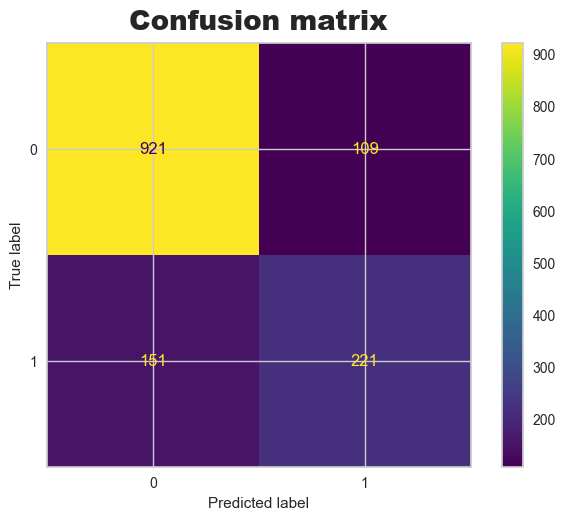

In [265]:
pipeline1.fit_transform(data)

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 922><b> Pipeline 2</b></a></h3>

In [267]:
# in this second pipeline we choose to drop missing values, the log function to transform numeric features, StandarScaler to scaling our data, no deal with class imbalance and CatBoostClassifier model
pipeline2 = Pipeline([
    ('drop customerid', drop_id('customerID')),
    ('deal_totalcharges', deal_totalcharges()),
    ('drop_duplicate', drop_duplicate()),
    ('imputer', imputer('drop')),
    ('transformation', transform_data('log')),
    ('encoder', encoder()),
    ('class imbalance', imbalance('No')),
    ('scaling', scaling(StandardScaler())), 
    ('split', split_data(0.6)), 
    ('training_model', training_model(CatBoostClassifier(verbose = 0, random_state = seed)))
])

In [268]:
pipeline2

Pipeline(memory=None,
         steps=[('drop customerid',
                 <__main__.drop_id object at 0x0000021142F97B50>),
                ('deal_totalcharges',
                 <__main__.deal_totalcharges object at 0x0000021142F97190>),
                ('drop_duplicate',
                 <__main__.drop_duplicate object at 0x00000211461B5A50>),
                ('imputer', <__main__.imputer object at 0x00000211461B6410>),
                ('transformation',
                 <__main__.transform_data object at 0x00000211461B5050>),
                ('encoder', <__main__.encoder object at 0x00000211461B45D0>),
                ('class imbalance',
                 <__main__.imbalance object at 0x00000211461B53D0>),
                ('scaling', <__main__.scaling object at 0x00000211479B79D0>),
                ('split', <__main__.split_data object at 0x00000211479B7050>),
                ('training_model',
                 <__main__.training_model object at 0x00000211479B74D0>)],
         verbose=False)

              precision    recall  f1-score      support
0              0.833184  0.901067  0.865797  1031.000000
1              0.644599  0.498652  0.562310   371.000000
accuracy       0.794579  0.794579  0.794579     0.794579
macro avg      0.738892  0.699860  0.714053  1402.000000
weighted avg   0.783280  0.794579  0.785488  1402.000000


<Figure size 1500x500 with 0 Axes>

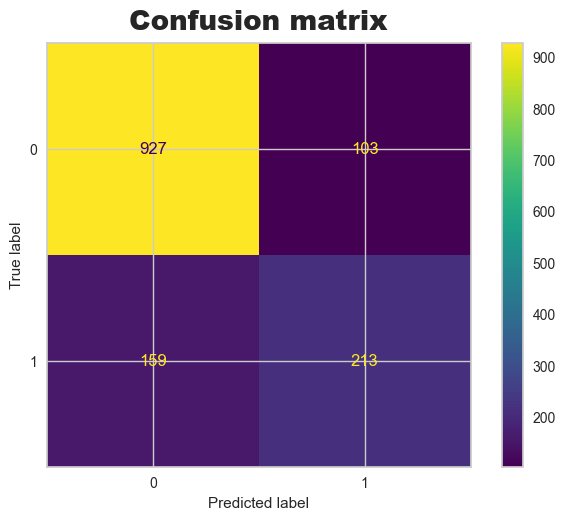

In [269]:
pipeline2.fit_transform(data)

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 923><b> Pipeline 3</b></a></h3>

In [271]:
# in this third pipeline we choose to drop missing values, the log function to transform numeric features, StandarScaler to scaling our data, no deal with class imbalance and LogisticRegression model
pipeline3 = Pipeline([
    ('drop customerid', drop_id('customerID')),
    ('deal_totalcharges', deal_totalcharges()),
    ('drop_duplicate', drop_duplicate()),
    ('imputer', imputer('drop')),
    ('transformation', transform_data('log')),
    ('encoder', encoder()),
   ('class imbalance', imbalance('No')),
    ('scaling', scaling(StandardScaler())), 
    ('split', split_data(0.6)), 
   ('training_model', training_model(LogisticRegression(C=10, random_state=seed)))
])

In [272]:
pipeline3

Pipeline(memory=None,
         steps=[('drop customerid',
                 <__main__.drop_id object at 0x000002112F371910>),
                ('deal_totalcharges',
                 <__main__.deal_totalcharges object at 0x000002112F371090>),
                ('drop_duplicate',
                 <__main__.drop_duplicate object at 0x000002112F373490>),
                ('imputer', <__main__.imputer object at 0x000002112F5409D0>),
                ('transformation',
                 <__main__.transform_data object at 0x00000211406D0A10>),
                ('encoder', <__main__.encoder object at 0x00000211406D0690>),
                ('class imbalance',
                 <__main__.imbalance object at 0x0000021148009210>),
                ('scaling', <__main__.scaling object at 0x0000021148008090>),
                ('split', <__main__.split_data object at 0x0000021148008F90>),
                ('training_model',
                 <__main__.training_model object at 0x00000211408CE0D0>)],
         verbose=False)

              precision    recall  f1-score      support
0              0.838104  0.908826  0.872034  1031.000000
1              0.669014  0.512129  0.580153   371.000000
accuracy       0.803852  0.803852  0.803852     0.803852
macro avg      0.753559  0.710478  0.726093  1402.000000
weighted avg   0.793359  0.803852  0.794795  1402.000000


<Figure size 1500x500 with 0 Axes>

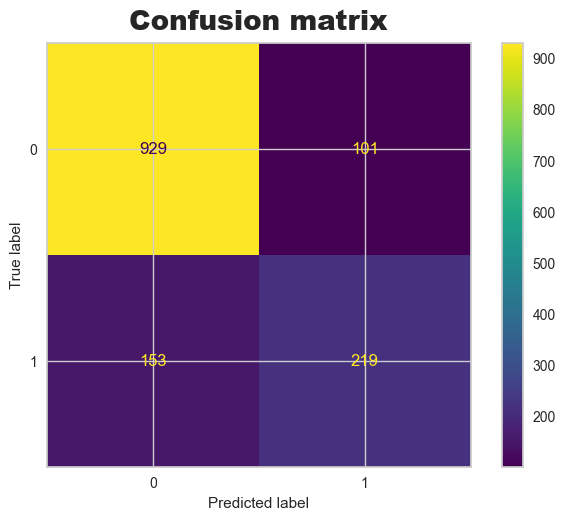

In [273]:
pipeline3.fit_transform(data)

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 924><b> Pipeline 4</b></a></h3>

In [275]:
# in this fourth pipeline we choose to drop missing values, the sqrt function to transform numeric features, MinMaxScaler to scaling our data, no deal with class imbalance and LogisticRegression model    
pipeline4 = Pipeline([
    ('drop customerid', drop_id('customerID')),
    ('deal_totalcharges', deal_totalcharges()),
    ('drop_duplicate', drop_duplicate()),
    ('imputer', imputer('drop')),
    ('transformation', transform_data('sqrt')),
    ('encoder', encoder()),
   ('class imbalance', imbalance('up')),
    ('scaling', scaling(MinMaxScaler())), 
    ('split', split_data(0.6)), 
   ('training_model', training_model(LogisticRegression(C=10, random_state=seed)))
])

In [276]:
pipeline4

Pipeline(memory=None,
         steps=[('drop customerid',
                 <__main__.drop_id object at 0x0000021148028D50>),
                ('deal_totalcharges',
                 <__main__.deal_totalcharges object at 0x000002114802BE90>),
                ('drop_duplicate',
                 <__main__.drop_duplicate object at 0x0000021148060DD0>),
                ('imputer', <__main__.imputer object at 0x0000021148062910>),
                ('transformation',
                 <__main__.transform_data object at 0x0000021148062850>),
                ('encoder', <__main__.encoder object at 0x0000021148061B50>),
                ('class imbalance',
                 <__main__.imbalance object at 0x00000211480625D0>),
                ('scaling', <__main__.scaling object at 0x0000021147F431D0>),
                ('split', <__main__.split_data object at 0x000002114809DF50>),
                ('training_model',
                 <__main__.training_model object at 0x0000021148062590>)],
         verbose=False)

              precision    recall  f1-score      support
0              0.787751  0.723569  0.754297  1031.000000
1              0.744395  0.805044  0.773532  1031.000000
accuracy       0.764306  0.764306  0.764306     0.764306
macro avg      0.766073  0.764306  0.763915  2062.000000
weighted avg   0.766073  0.764306  0.763915  2062.000000


<Figure size 1500x500 with 0 Axes>

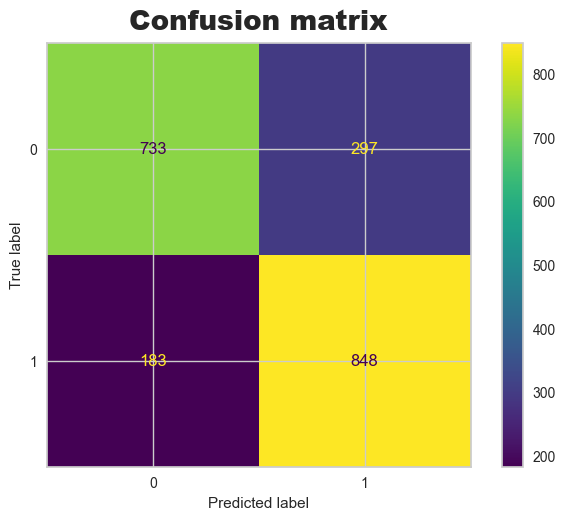

In [277]:
pipeline4.fit_transform(data)

<h1 style="background-color:#f8aa4b; font-size:36px; color:#602F44; padding : 10px; margin : 0"> <a id = 10><b> MLFLOW</b></a></h1>

- **I will save this experiment, and we will try to use df_mean, calss imbalance, ...**
- **One tool for save and log experiences is `MLFLOW`**
- **- MLflow is a solution that provides tools and simplifies processes to streamline the ML lifecycle and foster collaboration among ML practitioner . It provides a unified platform for model deployment and manageme**t.

In [280]:
# pip install pyngrok
# pip install mlflow

In [281]:
import mlflow

In [282]:
def log_metrics(model, X_train, y_train, X_test, y_test) :
  train_preds = model.predict(X_train)
  y_test_pred = model.predict(X_test)  
  # Confusion matrix  
  cm = confusion_matrix(y_test, y_test_pred)
  disp = ConfusionMatrixDisplay(confusion_matrix=cm)
  #matplotlib.use('module://ipykernel.pylab.backend_inline')
  #matplotlib.use('Agg')
  #plt.ioff() # disable affichage
  disp.plot()
  plt.title('Confusion matrix',fontweight='black',size=20,pad=10)
  plt.savefig('confusion_matrix.png')
  plt.close() # elle ne s'affiche pas

  # Log metrics (confusion matrix)
  mlflow.log_metric('true_positive', cm[0][0])
  mlflow.log_metric('true_negative', cm[1][1])
  mlflow.log_metric('false_positive', cm[0][1])
  mlflow.log_metric('false_negative', cm[1][0])  
    
  mlflow.log_artifact('confusion_matrix.png')
  
  # Log metrics (Classification report - accuracy)  
  report = classification_report(y_test, y_test_pred, output_dict=True)
  mlflow.log_metric('accuracy', report['accuracy'])

  # log some metrics
  test_mape = mean_absolute_percentage_error(y_test, y_test_pred) * 100
  r2 =  r2_score(y_test, y_test_pred)
  mlflow.log_metric('test_mape', test_mape)
  mlflow.log_metric('r2_score', r2) 
  return cm, report['accuracy']  

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 101><b> Experience 1  </b></a></h2>

- **We create 3 runs in this experience, using 3 differents algorithms, we log models and some metrics for each run**
- **We can do more runs with others algorithms**

In [285]:
mlflow.set_experiment("Exp1")
mlflow.sklearn.autolog(disable = True)

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 1011><b> Run 1 : CatBoostClassifier</b></a></h3>

In [501]:
with mlflow.start_run(run_name = 'CatBoostClassifier'):
  # train model
  model = CatBoostClassifier(verbose = 0, random_state = seed)
  model.fit(X_train, y_train)
  # Predict train data and test data
  train_preds = model.predict(X_train)
  y_test_pred = model.predict(X_test) 

  # log_metrics   
  log_metrics(model, X_train, y_train, X_test, y_test)
   
  # Save model
  mlflow.sklearn.log_model(model, 'CatBoostClassifier')
  ID = mlflow.active_run().info.run_uuid
  print("Model run ID: ", mlflow.active_run().info.run_uuid)

Model run ID:  f5f00fe2fd0a4635a7999c9f01fa12d1


In [288]:
# Load model
my_model = 'runs:/'+ID+'/CatBoostClassifier'
loaded_model = mlflow.pyfunc.load_model(my_model)
loaded_model

mlflow.pyfunc.loaded_model:
  artifact_path: CatBoostClassifier
  flavor: mlflow.sklearn
  run_id: c08ab6b26c8849f48b88b4a1837fee26

In [289]:
# predict X_val
preds = loaded_model.predict(X_val)
preds

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [290]:
# Confusion matrix and Accuracy
log_metrics(model, X_train, y_train, X_test, y_test)

(array([[927, 103],
        [159, 213]], dtype=int64),
 0.8131241084165478)

In [291]:
mlflow.end_run()
mlflow.sklearn.autolog(disable=True) 

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 1012><b> Run2 : Logistic Regression </b></a></h3>

In [293]:
with mlflow.start_run(run_name = 'LogesticRegression'):
  # train model
  model = LogisticRegression(C = 10, random_state = seed)
  model.fit(X_train, y_train)
  # log metrics  
  log_metrics(model, X_train, y_train, X_test, y_test)
  # Save model
  mlflow.sklearn.log_model(model, 'LogesticRegression')
  ID = mlflow.active_run().info.run_uuid

my_model = 'runs:/'+ID+'/LogesticRegression'
loaded_model = mlflow.pyfunc.load_model(my_model)
preds = loaded_model.predict(X_val)

# Confusion matrix and Accuracy
display(log_metrics(model, X_train, y_train, X_test, y_test))

mlflow.end_run()
mlflow.sklearn.autolog(disable=True) 

(array([[929, 101],
        [153, 219]], dtype=int64),
 0.818830242510699)

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 1013><b> Run3 : AdaBoostClassifier </b></a></h3>

In [295]:
with mlflow.start_run(run_name = 'AdaBoostClassifier'):
  # train model
  model = AdaBoostClassifier(learning_rate=1, random_state=seed)
  model.fit(X_train, y_train)
  # log metrics  
  log_metrics(model, X_train, y_train, X_test, y_test)
  # Save model
  mlflow.sklearn.log_model(model, 'AdaBoostClassifier')
  ID = mlflow.active_run().info.run_uuid

my_model = 'runs:/'+ID+'/AdaBoostClassifier'
loaded_model = mlflow.pyfunc.load_model(my_model)
preds = loaded_model.predict(X_val)

# Confusion matrix and Accuracy
display(log_metrics(model, X_train, y_train, X_test, y_test))

mlflow.end_run()
mlflow.sklearn.autolog(disable=True) 

(array([[921, 109],
        [151, 221]], dtype=int64),
 0.8145506419400856)

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 102><b> Experience 2 </b></a></h2>

- **In this experience, we use pipeline. We create some pipelines to deal with original data, then we apply one model (LogisticRegression in this experience) and save the experience with mlflow**
- **We can do more pipelines, we can choose other models, different functions to transform numeric features, different scalers, ...**   

In [298]:
mlflow.set_experiment("Exp2")
mlflow.sklearn.autolog(disable = True)

In [299]:
data = pd.read_csv('Customer_Churn.csv')

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 1021><b> Run 1 : Pipeline 1 </b></a></h3>

In [301]:
# in this first pipeline we choose to drop missing values, the log function to transform numeric features, StandarScaler to scaling our data and no deal with class imbalance  
pipeline1 = Pipeline([
    ('drop customerid', drop_id('customerID')),
    ('deal_totalcharges', deal_totalcharges()),
    ('drop_duplicate', drop_duplicate()),
    ('imputer', imputer('drop')),
    ('transformation', transform_data('log')),
    ('encoder', encoder()),
   ('class imbalance', imbalance('No')),
    ('scaling', scaling(StandardScaler())), 
    ('split', split_data(0.6))
])

In [302]:
with mlflow.start_run(run_name = 'Pipe1'):
  y, X_train, y_train, X_test, y_test, X_val, y_val = pipeline1.fit_transform(data)  
  # train model
  model = LogisticRegression(C = 10, random_state = seed)
  model.fit(X_train, y_train)
  # log metrics  
  log_metrics(model, X_train, y_train, X_test, y_test)
  # Save model
  mlflow.sklearn.log_model(model, 'Pipe1')
  ID = mlflow.active_run().info.run_uuid

my_model = 'runs:/'+ID+'/Pipe1'
loaded_model = mlflow.pyfunc.load_model(my_model)
preds = loaded_model.predict(X_val)

# Confusion matrix and Accuracy
display(log_metrics(model, X_train, y_train, X_test, y_test))

mlflow.end_run()
mlflow.sklearn.autolog(disable=True) 

(array([[929, 101],
        [153, 219]], dtype=int64),
 0.818830242510699)

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 1022><b> Run 2 : Pipeline 2 </b></a></h3>

In [304]:
# in this second pipeline we choose to drop missing values, the log function to transform numeric features, MinMaxScaler to scaling our data and deal class imbalance  
pipeline2 = Pipeline([
    ('drop customerid', drop_id('customerID')),
    ('deal_totalcharges', deal_totalcharges()),
    ('drop_duplicate', drop_duplicate()),
    ('imputer', imputer('drop')),
    ('transformation', transform_data('log')),
    ('encoder', encoder()),
   ('class imbalance', imbalance('up')),
    ('scaling', scaling(MinMaxScaler())), 
    ('split', split_data(0.6)), 
])

In [305]:
with mlflow.start_run(run_name = 'Pipe2'):
  y, X_train, y_train, X_test, y_test, X_val, y_val = pipeline2.fit_transform(data)  
  # train model
  model = LogisticRegression(C = 10, random_state = seed)
  model.fit(X_train, y_train)
  # log metrics  
  log_metrics(model, X_train, y_train, X_test, y_test)
  # Save model
  mlflow.sklearn.log_model(model, 'Pipe2')
  ID = mlflow.active_run().info.run_uuid

my_model = 'runs:/'+ID+'/Pipe2'
loaded_model = mlflow.pyfunc.load_model(my_model)
preds = loaded_model.predict(X_val)
# Confusion matrix and Accuracy
display(log_metrics(model, X_train, y_train, X_test, y_test))

mlflow.end_run()
mlflow.sklearn.autolog(disable=True) 

(array([[741, 289],
        [177, 854]], dtype=int64),
 0.7738961669092673)

<h3 style="background-color:#e6f598; font-family:newtimeroman;color:#602F44; font-size:20px; padding : 5px"> <a id = 1023><b> Run 3 : Pipeline 3 </b></a></h3>

In [307]:
# in this third pipeline we choose to drop missing values, the sqrt function to transform numeric features, RobustScaler to scaling our data and no deal with class imbalance  
pipeline3 = Pipeline([
    ('drop customerid', drop_id('customerID')),
    ('deal_totalcharges', deal_totalcharges()),
    ('drop_duplicate', drop_duplicate()),
    ('imputer', imputer('drop')),
    ('transformation', transform_data('sqrt')),
    ('encoder', encoder()),
   ('class imbalance', imbalance('No')),
    ('scaling', scaling(RobustScaler())), 
    ('split', split_data(0.6))
])

In [308]:
with mlflow.start_run(run_name = 'Pipe3'):
  y, X_train, y_train, X_test, y_test, X_val, y_val = pipeline3.fit_transform(data)  
  # train model
  model = LogisticRegression(C = 10, random_state = seed)
  model.fit(X_train, y_train)
  # log metrics  
  log_metrics(model, X_train, y_train, X_test, y_test)
  # Save model
  mlflow.sklearn.log_model(model, 'Pipe3')
  ID = mlflow.active_run().info.run_uuid

my_model = 'runs:/'+ID+'/Pipe3'
loaded_model = mlflow.pyfunc.load_model(my_model)
preds = loaded_model.predict(X_val)

# Confusion matrix and Accuracy
display(log_metrics(model, X_train, y_train, X_test, y_test))

mlflow.end_run()
mlflow.sklearn.autolog(disable=True) 

(array([[920, 110],
        [152, 220]], dtype=int64),
 0.8131241084165478)

<h2 style="background-color:#54d2d2; font-family:newtimeroman;color:#602F44; font-size:30px; padding : 5px"> <a id = 103><b> Pyngrok </b></a></h2>

- **Pyngrok allows the use of the mlflow graphical interface, where you can consult the experiments, the runs of each experiment and the metrics of each run**

In [ ]:
import os
from pyngrok import ngrok
# Terminate open tunnels if exist
ngrok.kill()

# Get your authtoken from https://dashboard.ngrok.com/auth
NGROK_AUTH_TOKEN = os.environ["NGROK_AUTH_TOKEN"]  # set it in your environment, never in the notebook
ngrok.set_auth_token(NGROK_AUTH_TOKEN)

# Open an HTTPs tunnel on port 5000 for http://localhost:5000
ngrok_tunnel = ngrok.connect(addr="5000", proto="http", bind_tls=True)
print("MLflow Tracking UI:", ngrok_tunnel.public_url)

In [503]:
!mlflow ui  
# (run this command to open mlflow tracking user interface)

^C


In [313]:
html1 = '<center><img src="fig1.png"><center/>'
HTML(html1)

In [314]:
html2 = '<center><img src="fig2.png"><center/>'
HTML(html2)

In [315]:
html3 = '<center><img src="fig3.png"><center/>'
HTML(html3)

- **Thanks**